In [2]:
import torch

In [2]:
from pathlib import Path
import json
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def show_annotation_by_index(
    index,
    image_dir=r"D:\resume\13 - mini teraffic\main\img",
    annotation_dir=r"D:\resume\13 - mini teraffic\main\ann"
):
 

    image_dir = Path(image_dir)
    annotation_dir = Path(annotation_dir)

    # --------------------------------------------------------
    # 1. پیدا کردن تصاویر
    # --------------------------------------------------------

    image_files = sorted([
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ])

    if len(image_files) == 0:
        raise FileNotFoundError(
            f"No image files found in:\n{image_dir}"
        )

    if index < 0 or index >= len(image_files):
        raise IndexError(
            f"Index {index} is out of range. "
            f"Valid range: 0 - {len(image_files) - 1}"
        )

    # --------------------------------------------------------
    # 2. انتخاب تصویر
    # --------------------------------------------------------

    image_path = image_files[index]
 
    annotation_path = annotation_dir / f"{image_path.name}.json"

    if not annotation_path.exists():
        raise FileNotFoundError(
            f"Annotation not found for:\n{image_path.name}\n"
            f"Expected:\n{annotation_path}"
        )

    # --------------------------------------------------------
    # 3. خواندن تصویر
    # --------------------------------------------------------

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(
            f"Could not read image:\n{image_path}"
        )

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # --------------------------------------------------------
    # 4. خواندن JSON
    # --------------------------------------------------------

    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    # --------------------------------------------------------
    # 5. استخراج Objectها
    # --------------------------------------------------------

    objects = annotation.get("objects", [])

    # --------------------------------------------------------
    # 6. نمایش تصویر
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(16, 10))

    ax.imshow(image)

    # --------------------------------------------------------
    # 7. رسم Bounding Boxها
    # --------------------------------------------------------

    for obj_index, obj in enumerate(objects):

        class_title = obj.get("classTitle", "Unknown")

        points = obj.get("points", {})
        exterior = points.get("exterior", [])

        if len(exterior) < 2:
            continue

        # تبدیل polygon به Bounding Box
        xs = [point[0] for point in exterior]
        ys = [point[1] for point in exterior]

        x_min = min(xs)
        y_min = min(ys)
        x_max = max(xs)
        y_max = max(ys)

        width = x_max - x_min
        height = y_max - y_min

        # رسم Bounding Box
        rect = patches.Rectangle(
            (x_min, y_min),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        # نمایش نام کلاس
        label = f"{class_title} | #{obj_index}"

        ax.text(
            x_min,
            max(0, y_min - 5),
            label,
            fontsize=10,
            color="white",
            backgroundcolor="red"
        )

    # --------------------------------------------------------
    # 8. عنوان
    # --------------------------------------------------------

    ax.set_title(
        f"Index: {index} | "
        f"Image: {image_path.name} | "
        f"Objects: {len(objects)}",
        fontsize=14
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 9. چاپ اطلاعات
    # --------------------------------------------------------

    print("=" * 80)
    print("IMAGE INFORMATION")
    print("=" * 80)

    print(f"Index        : {index}")
    print(f"Image        : {image_path.name}")
    print(f"Annotation   : {annotation_path.name}")
    print(f"Image Size   : {image.shape[1]} x {image.shape[0]}")
    print(f"Objects      : {len(objects)}")

    print("=" * 80)
    print("OBJECTS")
    print("=" * 80)

    for obj_index, obj in enumerate(objects):

        class_title = obj.get("classTitle", "Unknown")

        points = obj.get("points", {})
        exterior = points.get("exterior", [])

        if len(exterior) < 2:
            continue

        xs = [point[0] for point in exterior]
        ys = [point[1] for point in exterior]

        x_min = min(xs)
        y_min = min(ys)
        x_max = max(xs)
        y_max = max(ys)

        print(
            f"[{obj_index:02d}] "
            f"class={class_title:<15} "
            f"bbox=({x_min:.1f}, {y_min:.1f}, "
            f"{x_max:.1f}, {y_max:.1f}) "
            f"size=({x_max-x_min:.1f}, {y_max-y_min:.1f})"
        )

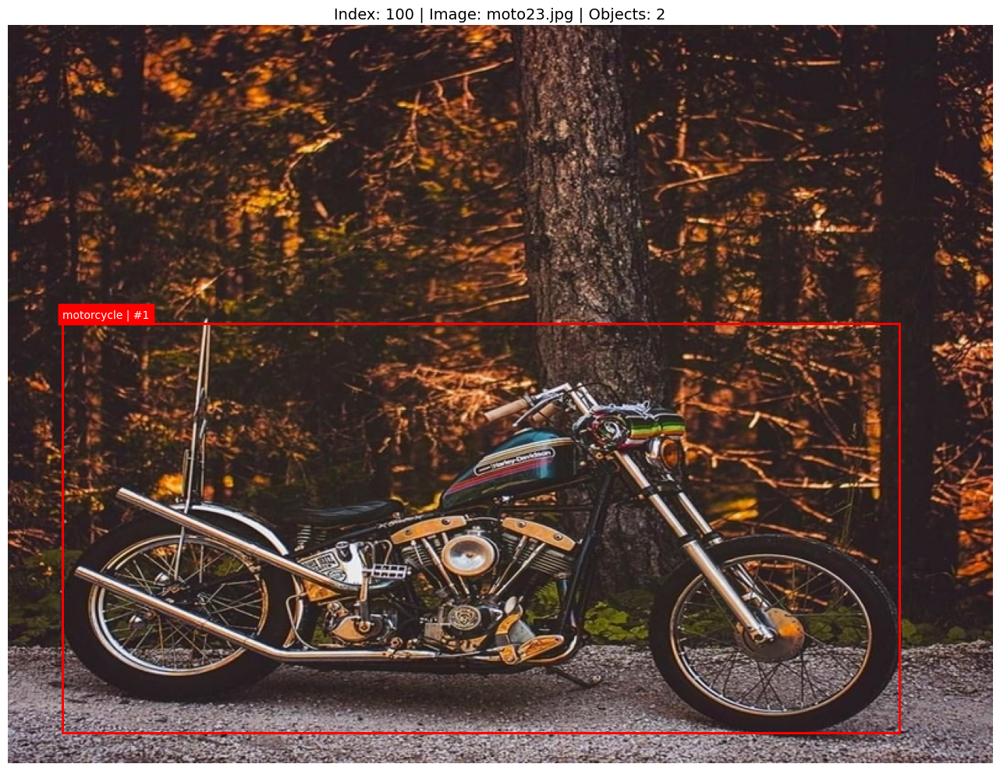

IMAGE INFORMATION
Index        : 100
Image        : moto23.jpg
Annotation   : moto23.jpg.json
Image Size   : 800 x 600
Objects      : 2
OBJECTS
[00] class=motorcycle      bbox=(44.0, 242.0, 724.0, 575.0) size=(680.0, 333.0)
[01] class=motorcycle      bbox=(44.0, 242.0, 724.0, 575.0) size=(680.0, 333.0)


In [3]:
show_annotation_by_index(100)

In [4]:
# ============================================================
# PHASE 1 - PROJECT CONFIGURATION & DATASET VALIDATION
# Mini Traffic Object Detection
# ============================================================
#
# INPUT:
#   img/  -> Images
#   ann/  -> Supervisely-style JSON annotations
#
# OUTPUT:
#   result/
#       configs/
#       dataset_info/
#       preprocessing/
#       splits/
#       visualizations/
#       checkpoints/
#       logs/
#       evaluation/
#       inference/
#
# IMPORTANT:
#   - Jupyter Notebook cell
#   - No main()
#   - No if __name__ == "__main__"
#   - No image preprocessing in Phase 1
#   - No silent overwriting of existing reports
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import json
import time
import hashlib
import platform
import sys

from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

import torch


# ============================================================
# 2. PROJECT CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(
    r"D:\resume\13 - mini teraffic\main"
)

IMAGE_DIR = PROJECT_ROOT / "img"
ANNOTATION_DIR = PROJECT_ROOT / "ann"
RESULT_DIR = PROJECT_ROOT / "result"


# ------------------------------------------------------------
# Training configuration
# These are project settings, not training execution.
# ------------------------------------------------------------

CONFIG = {
    "project_name": "Mini_Traffic_Object_Detection",

    "image_dir": str(IMAGE_DIR),
    "annotation_dir": str(ANNOTATION_DIR),
    "result_dir": str(RESULT_DIR),

    "image_size": 640,
    "batch_size": 4,
    "epochs": 20,

    "learning_rate": 1e-3,
    "weight_decay": 1e-4,

    "train_ratio": 0.80,
    "val_ratio": 0.10,
    "test_ratio": 0.10,

    "random_seed": 42,
    "num_workers": 0,

    "use_amp": True,

    "image_extensions": [
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp",
        ".tif",
        ".tiff",
    ],

    "annotation_extension": ".json",

    "created_at": datetime.now().isoformat(
        timespec="seconds"
    ),
}


# ============================================================
# 3. CREATE PROJECT OUTPUT DIRECTORIES
# ============================================================

OUTPUT_SUBDIRS = [
    "configs",
    "dataset_info",
    "preprocessing",
    "splits",
    "visualizations",
    "checkpoints",
    "logs",
    "evaluation",
    "inference",
]

print("=" * 72)
print("PHASE 1 - PROJECT INITIALIZATION")
print("=" * 72)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project root does not exist:\n{PROJECT_ROOT}"
    )

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Image directory does not exist:\n{IMAGE_DIR}"
    )

if not ANNOTATION_DIR.is_dir():
    raise FileNotFoundError(
        f"Annotation directory does not exist:\n"
        f"{ANNOTATION_DIR}"
    )

for folder_name in OUTPUT_SUBDIRS:
    folder_path = RESULT_DIR / folder_name
    folder_path.mkdir(
        parents=True,
        exist_ok=True
    )

    print(f"[OK] Output directory: {folder_path}")

print("\n[OK] All required input directories exist.")
print("[OK] Output directory structure is ready.")


# ============================================================
# 4. ENVIRONMENT INFORMATION
# ============================================================

print("\n" + "=" * 72)
print("ENVIRONMENT INFORMATION")
print("=" * 72)

print(f"Python version       : {sys.version.split()[0]}")
print(f"Operating system     : {platform.platform()}")
print(f"PyTorch version      : {torch.__version__}")
print(f"CUDA available       : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"CUDA version         : {torch.version.cuda}")
    print(f"GPU name             : {torch.cuda.get_device_name(0)}")

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        f"GPU memory           : "
        f"{gpu_properties.total_memory / (1024**3):.2f} GB"
    )
else:
    print("GPU name             : CPU")

print(f"\nProject root         : {PROJECT_ROOT}")
print(f"Images               : {IMAGE_DIR}")
print(f"Annotations          : {ANNOTATION_DIR}")
print(f"Results              : {RESULT_DIR}")


# ============================================================
# 5. DISCOVER IMAGE AND ANNOTATION FILES
# ============================================================

print("\n" + "=" * 72)
print("DISCOVERING DATASET FILES")
print("=" * 72)

IMAGE_EXTENSIONS = {
    ext.lower()
    for ext in CONFIG["image_extensions"]
}

image_paths = sorted(
    path
    for path in IMAGE_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
)

annotation_paths = sorted(
    path
    for path in ANNOTATION_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() == ".json"
)

print(f"Discovered images       : {len(image_paths)}")
print(f"Discovered annotations  : {len(annotation_paths)}")

if len(image_paths) == 0:
    raise RuntimeError(
        "No supported image files were found."
    )

if len(annotation_paths) == 0:
    raise RuntimeError(
        "No JSON annotation files were found."
    )


# ============================================================
# 6. BUILD FILE INDEX
# ============================================================
#
# Expected naming convention:
#   bicycle1.jpg
#   bicycle1.jpg.json
#
# Matching is based on the image filename, including its
# original extension, rather than only its stem.
# ============================================================

annotation_index = {}

duplicate_annotation_keys = []

for ann_path in annotation_paths:
    annotation_key = ann_path.name[:-5].lower()

    if annotation_key in annotation_index:
        duplicate_annotation_keys.append(
            annotation_key
        )
    else:
        annotation_index[annotation_key] = ann_path

if duplicate_annotation_keys:
    raise RuntimeError(
        "Multiple annotation files map to the same image key. "
        "Resolve duplicate annotation names before continuing:\n"
        + "\n".join(
            sorted(set(duplicate_annotation_keys))
        )
    )


image_index = {}

duplicate_image_keys = []

for image_path in image_paths:
    image_key = image_path.name.lower()

    if image_key in image_index:
        duplicate_image_keys.append(image_key)
    else:
        image_index[image_key] = image_path

if duplicate_image_keys:
    raise RuntimeError(
        "Duplicate image filenames were found in different "
        "subdirectories. The current matching strategy is "
        "ambiguous:\n"
        + "\n".join(sorted(set(duplicate_image_keys)))
    )


matched_keys = sorted(
    set(image_index) & set(annotation_index)
)

images_without_annotations = sorted(
    set(image_index) - set(annotation_index)
)

annotations_without_images = sorted(
    set(annotation_index) - set(image_index)
)

print(f"\nMatched image/annotation pairs : {len(matched_keys)}")
print(f"Images without annotations     : {len(images_without_annotations)}")
print(f"Annotations without images     : {len(annotations_without_images)}")

if images_without_annotations:
    print("\nExamples of images without annotations:")

    for key in images_without_annotations[:10]:
        print(f"  - {key}")

if annotations_without_images:
    print("\nExamples of annotations without images:")

    for key in annotations_without_images[:10]:
        print(f"  - {key}")


# ============================================================
# 7. VALIDATE IMAGE FILES
# ============================================================

print("\n" + "=" * 72)
print("VALIDATING IMAGE FILES")
print("=" * 72)

image_records = []
image_errors = []

for image_path in tqdm(
    image_paths,
    desc="Checking images",
    unit="image"
):
    record = {
        "image_path": str(image_path),
        "image_name": image_path.name,
        "width": None,
        "height": None,
        "mode": None,
        "format": None,
        "file_size_bytes": None,
        "is_readable": False,
        "error": None,
    }

    try:
        record["file_size_bytes"] = image_path.stat().st_size

        with Image.open(image_path) as image:
            image.verify()

        # Reopen because verify() invalidates normal image access.
        with Image.open(image_path) as image:
            image.load()

            record["width"] = image.width
            record["height"] = image.height
            record["mode"] = image.mode
            record["format"] = image.format
            record["is_readable"] = True

    except (
        OSError,
        ValueError,
        UnidentifiedImageError
    ) as exc:
        record["error"] = (
            f"{type(exc).__name__}: {exc}"
        )

        image_errors.append({
            "image_path": str(image_path),
            "error": record["error"],
        })

    image_records.append(record)


image_df = pd.DataFrame(image_records)

readable_image_df = image_df[
    image_df["is_readable"]
].copy()

print("\nImage validation summary")
print("-" * 50)
print(f"Total images       : {len(image_df)}")
print(f"Readable images    : {len(readable_image_df)}")
print(f"Unreadable images  : {len(image_errors)}")

if len(readable_image_df) > 0:
    print("\nImage dimensions")
    print(
        readable_image_df[
            ["width", "height"]
        ].describe().round(2)
    )

    print("\nImage modes")
    print(
        readable_image_df["mode"]
        .value_counts(dropna=False)
    )

    print("\nImage formats")
    print(
        readable_image_df["format"]
        .value_counts(dropna=False)
    )

if image_errors:
    print("\nUnreadable image examples:")

    for item in image_errors[:10]:
        print(f"  {item['image_path']}")
        print(f"    Error: {item['error']}")


# ============================================================
# 8. VALIDATE JSON ANNOTATION STRUCTURE
# ============================================================
#
# This stage checks JSON syntax and basic structure.
# Detailed bounding-box parsing and geometric validation
# will be implemented in later phases.
# ============================================================

print("\n" + "=" * 72)
print("VALIDATING ANNOTATION FILES")
print("=" * 72)

annotation_records = []
annotation_errors = []

for ann_path in tqdm(
    annotation_paths,
    desc="Checking annotations",
    unit="file"
):
    record = {
        "annotation_path": str(ann_path),
        "annotation_name": ann_path.name,
        "json_valid": False,
        "root_type": None,
        "objects_key_present": False,
        "object_count": None,
        "error": None,
    }

    try:
        with ann_path.open(
            "r",
            encoding="utf-8-sig"
        ) as file:
            data = json.load(file)

        record["root_type"] = type(data).__name__

        if not isinstance(data, dict):
            raise ValueError(
                "JSON root must be an object/dictionary."
            )

        if "objects" not in data:
            raise KeyError(
                "Required 'objects' key was not found."
            )

        if not isinstance(data["objects"], list):
            raise TypeError(
                "'objects' must contain a list."
            )

        record["json_valid"] = True
        record["objects_key_present"] = True
        record["object_count"] = len(data["objects"])

    except (
        OSError,
        UnicodeError,
        json.JSONDecodeError,
        ValueError,
        TypeError,
        KeyError
    ) as exc:
        record["error"] = (
            f"{type(exc).__name__}: {exc}"
        )

        annotation_errors.append({
            "annotation_path": str(ann_path),
            "error": record["error"],
        })

    annotation_records.append(record)


annotation_df = pd.DataFrame(annotation_records)

valid_annotation_df = annotation_df[
    annotation_df["json_valid"]
].copy()

print("\nAnnotation validation summary")
print("-" * 50)
print(f"Total JSON files          : {len(annotation_df)}")
print(f"Valid annotation files    : {len(valid_annotation_df)}")
print(f"Invalid annotation files  : {len(annotation_errors)}")

if len(valid_annotation_df) > 0:
    total_raw_objects = int(
        valid_annotation_df["object_count"].sum()
    )

    print(f"Total raw objects         : {total_raw_objects}")

    print("\nObjects per annotation")
    print(
        valid_annotation_df["object_count"]
        .describe()
        .round(2)
    )

if annotation_errors:
    print("\nInvalid annotation examples:")

    for item in annotation_errors[:10]:
        print(f"  {item['annotation_path']}")
        print(f"    Error: {item['error']}")


# ============================================================
# 9. VALIDATE MATCHED PAIRS
# ============================================================

print("\n" + "=" * 72)
print("MATCHED PAIR VALIDATION")
print("=" * 72)

image_readability = {
    row["image_name"].lower(): bool(row["is_readable"])
    for row in image_records
}

annotation_validity = {
    row["annotation_name"][:-5].lower(): bool(row["json_valid"])
    for row in annotation_records
}

pair_records = []

for key in matched_keys:
    image_path = image_index[key]
    ann_path = annotation_index[key]

    image_ok = image_readability.get(key, False)
    ann_ok = annotation_validity.get(key, False)

    pair_records.append({
        "image_name": image_path.name,
        "image_path": str(image_path),
        "annotation_name": ann_path.name,
        "annotation_path": str(ann_path),
        "image_readable": image_ok,
        "annotation_valid": ann_ok,
        "pair_usable": image_ok and ann_ok,
    })


pairs_df = pd.DataFrame(
    pair_records,
    columns=[
        "image_name",
        "image_path",
        "annotation_name",
        "annotation_path",
        "image_readable",
        "annotation_valid",
        "pair_usable",
    ]
)

usable_pairs_df = pairs_df[
    pairs_df["pair_usable"]
].copy()

print(f"Matched pairs       : {len(pairs_df)}")
print(f"Usable pairs        : {len(usable_pairs_df)}")
print(
    f"Unusable matched pairs: "
    f"{len(pairs_df) - len(usable_pairs_df)}"
)


# ============================================================
# 10. SAVE CONFIGURATION AND VALIDATION REPORTS
# ============================================================

print("\n" + "=" * 72)
print("SAVING PHASE 1 REPORTS")
print("=" * 72)

CONFIG_PATH = RESULT_DIR / "configs" / "project_config.json"

IMAGE_REPORT_PATH = (
    RESULT_DIR / "dataset_info" / "image_validation.csv"
)

ANNOTATION_REPORT_PATH = (
    RESULT_DIR / "dataset_info" / "annotation_validation.csv"
)

PAIR_REPORT_PATH = (
    RESULT_DIR / "dataset_info" / "matched_pairs.csv"
)

SUMMARY_PATH = (
    RESULT_DIR / "dataset_info" / "phase1_summary.json"
)

ERROR_REPORT_PATH = (
    RESULT_DIR / "dataset_info" / "phase1_errors.json"
)


def save_json_without_overwrite(path, data):
    """Save JSON without silently overwriting an existing file."""
    if path.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing file:\n{path}\n"
            "Move/delete it manually or choose a new report name."
        )

    with path.open(
        "x",
        encoding="utf-8"
    ) as file:
        json.dump(
            data,
            file,
            ensure_ascii=False,
            indent=4
        )


def save_csv_without_overwrite(dataframe, path):
    """Save CSV without silently overwriting an existing file."""
    if path.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing file:\n{path}\n"
            "Move/delete it manually or choose a new report name."
        )

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        mode="x"
    )


phase1_summary = {
    "project_name": CONFIG["project_name"],
    "timestamp": datetime.now().isoformat(
        timespec="seconds"
    ),

    "project_root": str(PROJECT_ROOT),
    "image_directory": str(IMAGE_DIR),
    "annotation_directory": str(ANNOTATION_DIR),
    "result_directory": str(RESULT_DIR),

    "total_images": int(len(image_paths)),
    "readable_images": int(len(readable_image_df)),
    "unreadable_images": int(len(image_errors)),

    "total_annotations": int(len(annotation_paths)),
    "valid_annotations": int(len(valid_annotation_df)),
    "invalid_annotations": int(len(annotation_errors)),

    "matched_pairs": int(len(pairs_df)),
    "usable_pairs": int(len(usable_pairs_df)),
    "unusable_matched_pairs": int(
        len(pairs_df) - len(usable_pairs_df)
    ),

    "images_without_annotations": int(
        len(images_without_annotations)
    ),
    "annotations_without_images": int(
        len(annotations_without_images)
    ),

    "total_raw_objects_in_valid_json": int(
        valid_annotation_df["object_count"].sum()
    ) if len(valid_annotation_df) else 0,

    "image_dimensions": {
        "width_min": int(readable_image_df["width"].min()),
        "width_mean": float(readable_image_df["width"].mean()),
        "width_median": float(readable_image_df["width"].median()),
        "width_max": int(readable_image_df["width"].max()),

        "height_min": int(readable_image_df["height"].min()),
        "height_mean": float(readable_image_df["height"].mean()),
        "height_median": float(readable_image_df["height"].median()),
        "height_max": int(readable_image_df["height"].max()),
    } if len(readable_image_df) else {},

    "configuration": CONFIG,
}


error_report = {
    "image_errors": image_errors,
    "annotation_errors": annotation_errors,
    "images_without_annotations": [
        str(image_index[key])
        for key in images_without_annotations
    ],
    "annotations_without_images": [
        str(annotation_index[key])
        for key in annotations_without_images
    ],
}


# Preflight: check all destinations before writing anything.
report_paths = [
    CONFIG_PATH,
    IMAGE_REPORT_PATH,
    ANNOTATION_REPORT_PATH,
    PAIR_REPORT_PATH,
    SUMMARY_PATH,
    ERROR_REPORT_PATH,
]

existing_reports = [
    path for path in report_paths
    if path.exists()
]

if existing_reports:
    print("\nExisting report files detected:")

    for path in existing_reports:
        print(f"  - {path}")

    raise FileExistsError(
        "No reports were written because one or more target "
        "files already exist. Inspect the listed files and "
        "remove or rename them manually before rerunning."
    )


save_json_without_overwrite(
    CONFIG_PATH,
    CONFIG
)

save_csv_without_overwrite(
    image_df,
    IMAGE_REPORT_PATH
)

save_csv_without_overwrite(
    annotation_df,
    ANNOTATION_REPORT_PATH
)

save_csv_without_overwrite(
    pairs_df,
    PAIR_REPORT_PATH
)

save_json_without_overwrite(
    SUMMARY_PATH,
    phase1_summary
)

save_json_without_overwrite(
    ERROR_REPORT_PATH,
    error_report
)

print("[OK] Configuration saved.")
print("[OK] Image validation report saved.")
print("[OK] Annotation validation report saved.")
print("[OK] Matched-pairs report saved.")
print("[OK] Phase 1 summary saved.")
print("[OK] Error report saved.")


# ============================================================
# 11. FINAL PHASE 1 SUMMARY
# ============================================================

print("\n" + "=" * 72)
print("PHASE 1 - FINAL SUMMARY")
print("=" * 72)

print(f"Images discovered            : {len(image_paths)}")
print(f"Readable images              : {len(readable_image_df)}")
print(f"Annotations discovered       : {len(annotation_paths)}")
print(f"Valid JSON annotations       : {len(valid_annotation_df)}")
print(f"Matched pairs                : {len(pairs_df)}")
print(f"Usable matched pairs         : {len(usable_pairs_df)}")
print(f"Unreadable images            : {len(image_errors)}")
print(f"Invalid annotations          : {len(annotation_errors)}")
print(f"Images without annotations   : {len(images_without_annotations)}")
print(f"Annotations without images   : {len(annotations_without_images)}")

print("\nReport directory:")
print(RESULT_DIR / "dataset_info")

print("\nPhase 1 completed.")
print(
    "Note: Detailed polygon/bounding-box validation, "
    "class-frequency analysis and geometric checks will be "
    "performed in subsequent phases."
)


PHASE 1 - PROJECT INITIALIZATION
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\configs
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\dataset_info
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\preprocessing
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\splits
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\visualizations
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\checkpoints
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\logs
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\evaluation
[OK] Output directory: D:\resume\13 - mini teraffic\main\result\inference

[OK] All required input directories exist.
[OK] Output directory structure is ready.

ENVIRONMENT INFORMATION
Python version       : 3.10.11
Operating system     : Windows-10-10.0.22631-SP0
PyTorch version      : 2.9.0+cu126
CUDA available       : True
CUDA version         : 12.6
GPU name      

Checking images:   0%|          | 0/226 [00:00<?, ?image/s]


Image validation summary
--------------------------------------------------
Total images       : 226
Readable images    : 226
Unreadable images  : 0

Image dimensions
       width  height
count  226.0   226.0
mean   800.0   600.0
std      0.0     0.0
min    800.0   600.0
25%    800.0   600.0
50%    800.0   600.0
75%    800.0   600.0
max    800.0   600.0

Image modes
RGB     223
L         2
CMYK      1
Name: mode, dtype: int64

Image formats
JPEG    226
Name: format, dtype: int64

VALIDATING ANNOTATION FILES


Checking annotations:   0%|          | 0/226 [00:00<?, ?file/s]


Annotation validation summary
--------------------------------------------------
Total JSON files          : 226
Valid annotation files    : 226
Invalid annotation files  : 0
Total raw objects         : 725

Objects per annotation
count    226.00
mean       3.21
std        2.90
min        2.00
25%        2.00
50%        2.00
75%        2.00
max       20.00
Name: object_count, dtype: float64

MATCHED PAIR VALIDATION
Matched pairs       : 226
Usable pairs        : 226
Unusable matched pairs: 0

SAVING PHASE 1 REPORTS
[OK] Configuration saved.
[OK] Image validation report saved.
[OK] Annotation validation report saved.
[OK] Matched-pairs report saved.
[OK] Phase 1 summary saved.
[OK] Error report saved.

PHASE 1 - FINAL SUMMARY
Images discovered            : 226
Readable images              : 226
Annotations discovered       : 226
Valid JSON annotations       : 226
Matched pairs                : 226
Usable matched pairs         : 226
Unreadable images            : 0
Invalid annotations  

PHASE 2 - PREPROCESSING EDA
Images       : 226
Target size  : 640 x 640
Output       : D:\resume\13 - mini teraffic\main\result\preprocessing\phase2_eda_20261009_210252


Analyzing images:   0%|          | 0/226 [00:00<?, ?image/s]


Readable images: 226
Failed images  : 0

10 NUMERICAL INDICATORS

[01] Image dimensions and aspect ratio
{
  "width_min": 800.0,
  "width_mean": 800.0,
  "width_median": 800.0,
  "width_max": 800.0,
  "height_min": 600.0,
  "height_mean": 600.0,
  "height_median": 600.0,
  "height_max": 600.0,
  "aspect_ratio_min": 1.3333333333333333,
  "aspect_ratio_mean": 1.3333333333333333,
  "aspect_ratio_median": 1.3333333333333333,
  "aspect_ratio_max": 1.3333333333333333
}
Decision: Evaluate aspect-ratio preservation before square resizing.

[02] Resolution and pixel count
{
  "pixels_min": 480000,
  "pixels_mean": 480000.0,
  "pixels_median": 480000.0,
  "pixels_max": 480000,
  "target_pixels": 409600
}
Decision: Balance target resolution, object detail, and GPU memory.

[03] Mean luminance
{
  "mean": 123.5252405605485,
  "median": 122.38741302490234,
  "min": 21.340923309326172,
  "max": 236.69082641601562
}
Decision: Inspect dark and bright outliers before brightness correction.

[04] Lumin

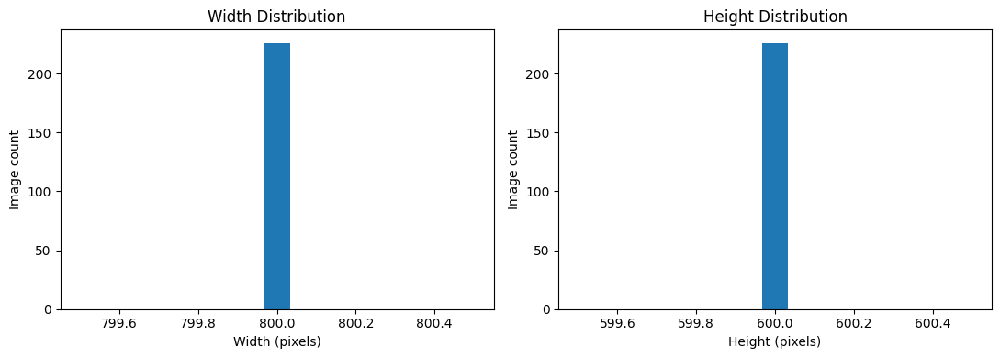

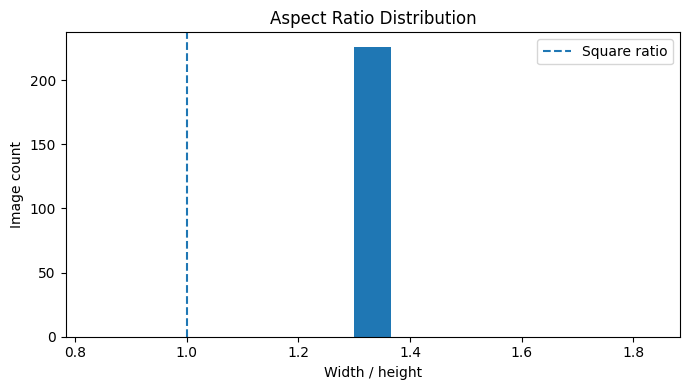

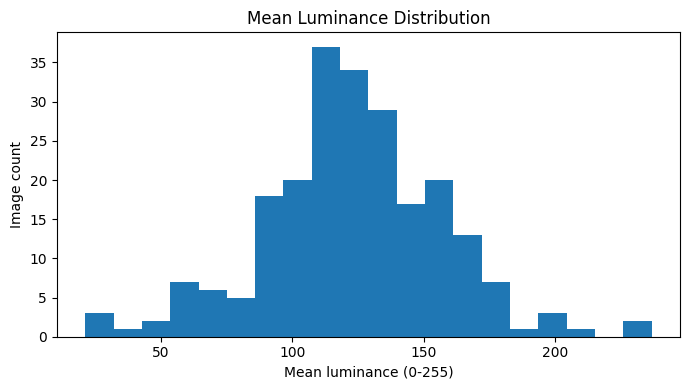

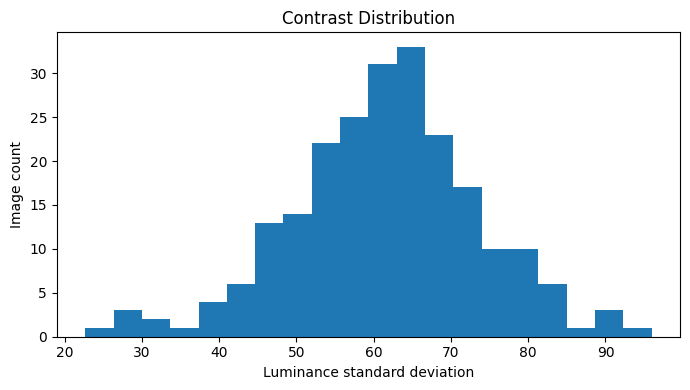

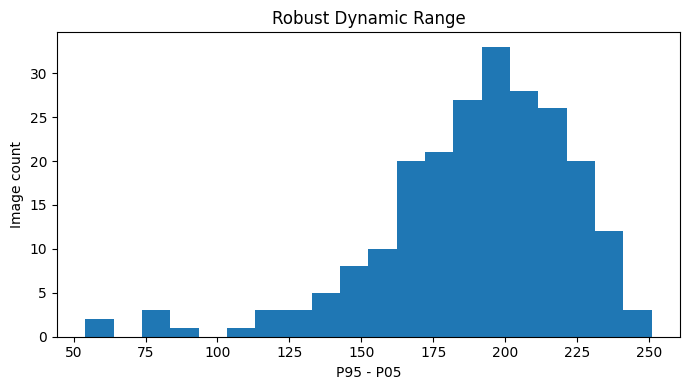

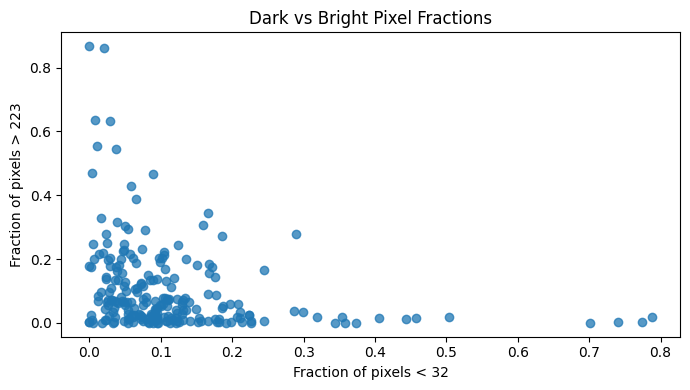

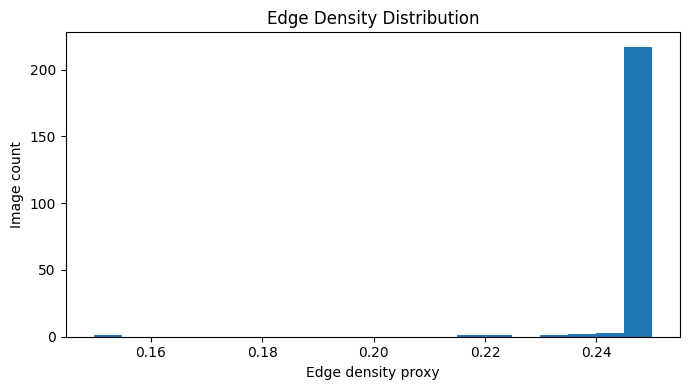

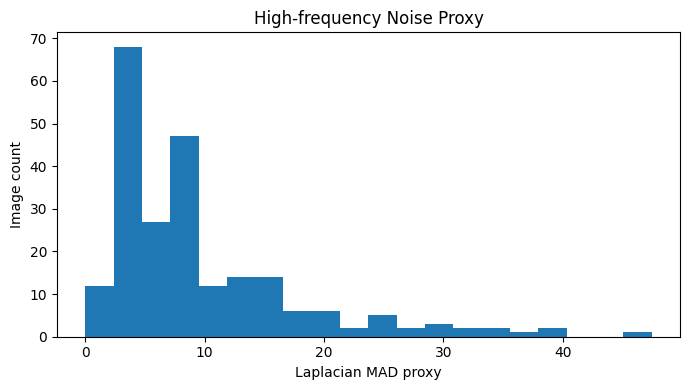

C:\Users\ASUS\AppData\Local\Temp\ipykernel_6140\2488591532.py:591: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=[str(mode) for mode in modes])


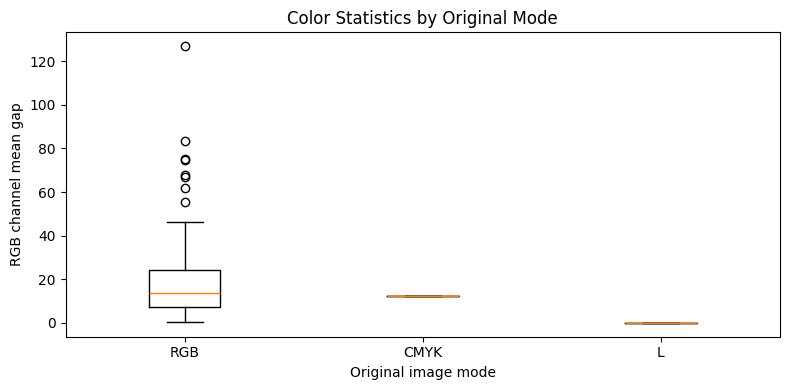

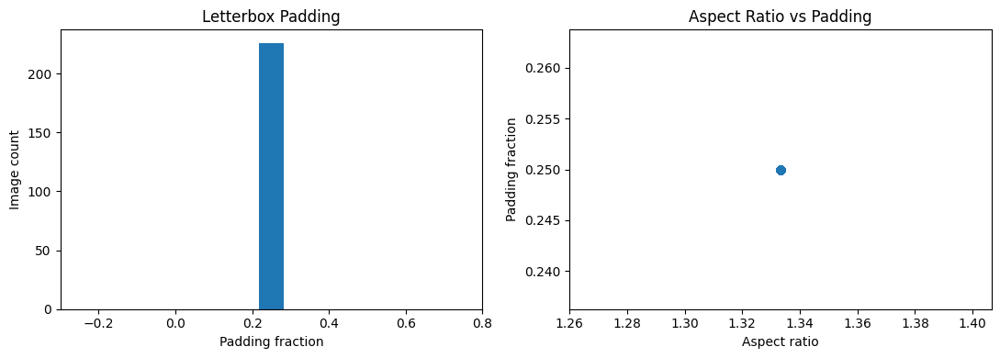


10 CHART INDICATORS

[01] Width and height distributions
Saved: D:\resume\13 - mini teraffic\main\result\preprocessing\phase2_eda_20261009_210252\charts\01_width_height.png
Interpretation: Fixed dimensions simplify batching; variable dimensions require consistent geometry handling.

[02] Aspect ratio
Saved: D:\resume\13 - mini teraffic\main\result\preprocessing\phase2_eda_20261009_210252\charts\02_aspect_ratio.png
Interpretation: Ratios far from 1 indicate that direct square resizing may distort shapes.

[03] Mean luminance
Saved: D:\resume\13 - mini teraffic\main\result\preprocessing\phase2_eda_20261009_210252\charts\03_mean_luminance.png
Interpretation: Identify unusually dark or bright images before applying intensity corrections.

[04] Contrast
Saved: D:\resume\13 - mini teraffic\main\result\preprocessing\phase2_eda_20261009_210252\charts\04_contrast.png
Interpretation: A low-contrast tail can motivate testing CLAHE against the original images.

[05] Dynamic range
Saved: D:\resume

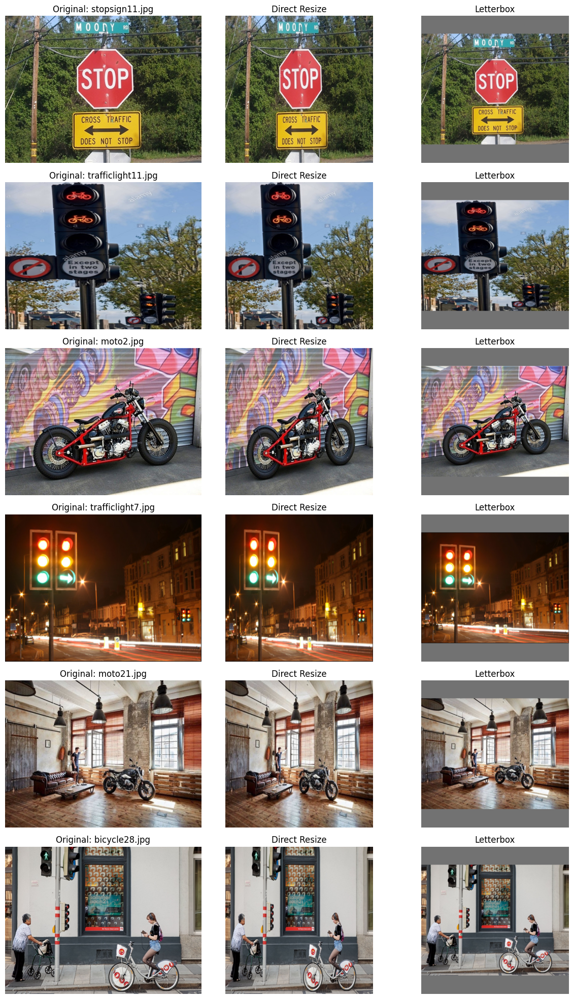


Visual comparison saved:
D:\resume\13 - mini teraffic\main\result\preprocessing\phase2_eda_20261009_210252\charts\11_visual_resize_comparison.png

PREPROCESSING DECISION ENGINE

1. Resize
   Decision : Resize to 640x640; compare direct resize and letterbox.
   Reason   : Aspect ratios are consistent; standard deviation=0.00000.
   Priority : high

2. Letterbox
   Decision : Review padding cost and compare against direct resize.
   Reason   : Mean padding fraction=0.2500.
   Priority : medium

3. Color conversion
   Decision : Required: convert all images consistently to RGB.
   Reason   : Detected original modes: {'RGB': 223, 'L': 2, 'CMYK': 1}.
   Priority : high

4. CLAHE
   Decision : Not justified by global statistics alone; retain as an ablation candidate.
   Reason   : Mean contrast=61.45; median dynamic range=194.00.
   Priority : low

5. Brightness correction
   Decision : No global correction indicated by these thresholds.
   Reason   : Mean dark fraction=0.114; bright fracti

In [5]:
# ============================================================
# PHASE 2 - PREPROCESSING EDA
# Mini Traffic Object Detection
# Exactly 10 Numerical + 10 Chart Indicators
# ============================================================

from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(r"D:\resume\13 - mini teraffic\main")
IMAGE_DIR = PROJECT_ROOT / "img"
ANNOTATION_DIR = PROJECT_ROOT / "ann"
RESULT_DIR = PROJECT_ROOT / "result"

OUTPUT_ROOT = RESULT_DIR / "preprocessing"
TARGET_SIZE = 640
RANDOM_SEED = 42

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")

if not ANNOTATION_DIR.is_dir():
    raise FileNotFoundError(
        f"Annotation directory not found: {ANNOTATION_DIR}"
    )

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

IMAGE_PATHS = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not IMAGE_PATHS:
    raise RuntimeError("No images found.")

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = OUTPUT_ROOT / f"phase2_eda_{RUN_ID}"
CHART_DIR = RUN_DIR / "charts"

RUN_DIR.mkdir()
CHART_DIR.mkdir()

print("=" * 72)
print("PHASE 2 - PREPROCESSING EDA")
print("=" * 72)
print(f"Images       : {len(IMAGE_PATHS)}")
print(f"Target size  : {TARGET_SIZE} x {TARGET_SIZE}")
print(f"Output       : {RUN_DIR}")


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def get_letterbox_geometry(width, height, target):
    scale = min(target / width, target / height)

    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))

    padding_width = target - new_width
    padding_height = target - new_height

    padding_fraction = (
        target**2 - new_width * new_height
    ) / target**2

    return (
        scale,
        new_width,
        new_height,
        padding_width,
        padding_height,
        padding_fraction,
    )


def calculate_edges(gray):
    gx = np.zeros_like(gray, dtype=np.float32)
    gy = np.zeros_like(gray, dtype=np.float32)

    gx[:, 1:-1] = (
        gray[:, 2:] - gray[:, :-2]
    ) / 2.0

    gy[1:-1, :] = (
        gray[2:, :] - gray[:-2, :]
    ) / 2.0

    magnitude = np.sqrt(gx**2 + gy**2)
    threshold = np.percentile(magnitude, 75)

    density = np.mean(magnitude > max(threshold, 1e-6))

    return float(density), magnitude


def calculate_noise_proxy(gray):
    # Approximate high-frequency response, not a calibrated
    # sensor-noise measurement.
    laplacian = (
        -4 * gray
        + np.roll(gray, 1, axis=0)
        + np.roll(gray, -1, axis=0)
        + np.roll(gray, 1, axis=1)
        + np.roll(gray, -1, axis=1)
    )

    laplacian = laplacian[1:-1, 1:-1]

    median = np.median(laplacian)
    mad = np.median(np.abs(laplacian - median))

    return float(mad / 0.6745)


def save_json_exclusive(path, data):
    if path.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing file: {path}"
        )

    with path.open("x", encoding="utf-8") as file:
        json.dump(data, file, indent=4, ensure_ascii=False)


def save_csv_exclusive(dataframe, path):
    if path.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing file: {path}"
        )

    dataframe.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        mode="x",
    )


def save_chart(filename):
    path = CHART_DIR / filename

    if path.exists():
        raise FileExistsError(
            f"Chart already exists: {path}"
        )

    # تنظیمات نهایی نمودار
    plt.tight_layout()

    # ذخیره نمودار روی دیسک
    plt.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    # نمایش نمودار داخل سلول Jupyter
    plt.show()

    # آزادسازی حافظه پس از نمایش
    plt.close("all")

    return str(path)




# ============================================================
# 3. ANALYZE ALL IMAGES
# ============================================================

records = []
image_cache = []

for image_path in tqdm(
    IMAGE_PATHS,
    desc="Analyzing images",
    unit="image",
):
    record = {
        "image_name": image_path.name,
        "image_path": str(image_path),
        "file_size_kb": np.nan,
        "width": np.nan,
        "height": np.nan,
        "aspect_ratio": np.nan,
        "pixel_count": np.nan,
        "image_mode": None,
        "mean_luminance": np.nan,
        "std_luminance": np.nan,
        "p05_luminance": np.nan,
        "p50_luminance": np.nan,
        "p95_luminance": np.nan,
        "dynamic_range": np.nan,
        "dark_fraction": np.nan,
        "bright_fraction": np.nan,
        "edge_density": np.nan,
        "noise_proxy": np.nan,
        "rgb_channel_gap": np.nan,
        "letterbox_padding_fraction": np.nan,
        "resize_scale": np.nan,
        "resized_width": np.nan,
        "resized_height": np.nan,
        "read_error": None,
    }

    try:
        record["file_size_kb"] = (
            image_path.stat().st_size / 1024
        )

        with Image.open(image_path) as image:
            record["image_mode"] = image.mode
            record["width"], record["height"] = image.size

            rgb = np.asarray(
                image.convert("RGB"),
                dtype=np.uint8,
            )

        width = record["width"]
        height = record["height"]

        gray = np.asarray(
            Image.fromarray(rgb).convert("L"),
            dtype=np.float32,
        )

        p05, p50, p95 = np.percentile(
            gray, [5, 50, 95]
        )

        edge_density, gradient = calculate_edges(gray)

        geometry = get_letterbox_geometry(
            width, height, TARGET_SIZE
        )

        scale, new_w, new_h, pad_w, pad_h, padding = geometry

        channel_means = rgb.mean(axis=(0, 1))

        record.update({
            "aspect_ratio": width / height,
            "pixel_count": width * height,

            "mean_luminance": float(gray.mean()),
            "std_luminance": float(gray.std()),

            "p05_luminance": float(p05),
            "p50_luminance": float(p50),
            "p95_luminance": float(p95),
            "dynamic_range": float(p95 - p05),

            "dark_fraction": float(np.mean(gray < 32)),
            "bright_fraction": float(np.mean(gray > 223)),

            "edge_density": edge_density,
            "noise_proxy": calculate_noise_proxy(gray),

            "rgb_channel_gap": float(
                channel_means.max() - channel_means.min()
            ),

            "letterbox_padding_fraction": float(padding),
            "resize_scale": float(scale),
            "resized_width": int(new_w),
            "resized_height": int(new_h),
        })

        image_cache.append({
            "path": image_path,
            "rgb": rgb,
        })

    except Exception as exc:
        record["read_error"] = (
            f"{type(exc).__name__}: {exc}"
        )

    records.append(record)


df = pd.DataFrame(records)

valid_df = df[
    df["read_error"].isna()
].copy()

if valid_df.empty:
    raise RuntimeError("No readable images available for EDA.")

print("\nReadable images:", len(valid_df))
print("Failed images  :", int(df["read_error"].notna().sum()))


# ============================================================
# 4. EXACTLY 10 NUMERICAL INDICATORS
# ============================================================

mode_counts = {
    str(key): int(value)
    for key, value in valid_df["image_mode"].value_counts().items()
}

numeric_indicators = [
    {
        "id": 1,
        "name": "Image dimensions and aspect ratio",
        "values": {
            "width_min": float(valid_df.width.min()),
            "width_mean": float(valid_df.width.mean()),
            "width_median": float(valid_df.width.median()),
            "width_max": float(valid_df.width.max()),
            "height_min": float(valid_df.height.min()),
            "height_mean": float(valid_df.height.mean()),
            "height_median": float(valid_df.height.median()),
            "height_max": float(valid_df.height.max()),
            "aspect_ratio_min": float(valid_df.aspect_ratio.min()),
            "aspect_ratio_mean": float(valid_df.aspect_ratio.mean()),
            "aspect_ratio_median": float(valid_df.aspect_ratio.median()),
            "aspect_ratio_max": float(valid_df.aspect_ratio.max()),
        },
        "decision": "Evaluate aspect-ratio preservation before square resizing.",
    },
    {
        "id": 2,
        "name": "Resolution and pixel count",
        "values": {
            "pixels_min": int(valid_df.pixel_count.min()),
            "pixels_mean": float(valid_df.pixel_count.mean()),
            "pixels_median": float(valid_df.pixel_count.median()),
            "pixels_max": int(valid_df.pixel_count.max()),
            "target_pixels": TARGET_SIZE**2,
        },
        "decision": "Balance target resolution, object detail, and GPU memory.",
    },
    {
        "id": 3,
        "name": "Mean luminance",
        "values": {
            "mean": float(valid_df.mean_luminance.mean()),
            "median": float(valid_df.mean_luminance.median()),
            "min": float(valid_df.mean_luminance.min()),
            "max": float(valid_df.mean_luminance.max()),
        },
        "decision": "Inspect dark and bright outliers before brightness correction.",
    },
    {
        "id": 4,
        "name": "Luminance contrast",
        "values": {
            "mean": float(valid_df.std_luminance.mean()),
            "median": float(valid_df.std_luminance.median()),
            "p10": float(valid_df.std_luminance.quantile(0.10)),
            "p90": float(valid_df.std_luminance.quantile(0.90)),
        },
        "decision": "Low contrast can motivate a controlled CLAHE comparison.",
    },
    {
        "id": 5,
        "name": "Robust dynamic range P95-P05",
        "values": {
            "mean": float(valid_df.dynamic_range.mean()),
            "median": float(valid_df.dynamic_range.median()),
            "p10": float(valid_df.dynamic_range.quantile(0.10)),
            "p90": float(valid_df.dynamic_range.quantile(0.90)),
        },
        "decision": "Narrow dynamic range may justify contrast enhancement testing.",
    },
    {
        "id": 6,
        "name": "Dark and bright pixel fractions",
        "values": {
            "dark_mean": float(valid_df.dark_fraction.mean()),
            "dark_median": float(valid_df.dark_fraction.median()),
            "bright_mean": float(valid_df.bright_fraction.mean()),
            "bright_median": float(valid_df.bright_fraction.median()),
        },
        "decision": "Check clipping and extreme brightness before applying correction.",
    },
    {
        "id": 7,
        "name": "Edge density proxy",
        "values": {
            "mean": float(valid_df.edge_density.mean()),
            "median": float(valid_df.edge_density.median()),
            "p10": float(valid_df.edge_density.quantile(0.10)),
            "p90": float(valid_df.edge_density.quantile(0.90)),
        },
        "decision": "Use visual examples to distinguish useful detail from noise.",
    },
    {
        "id": 8,
        "name": "High-frequency noise proxy",
        "values": {
            "mean": float(valid_df.noise_proxy.mean()),
            "median": float(valid_df.noise_proxy.median()),
            "p90": float(valid_df.noise_proxy.quantile(0.90)),
        },
        "decision": "Do not denoise unless visual inspection confirms harmful noise.",
    },
    {
        "id": 9,
        "name": "Color consistency",
        "values": {
            "mean_channel_gap": float(valid_df.rgb_channel_gap.mean()),
            "median_channel_gap": float(valid_df.rgb_channel_gap.median()),
            "p90_channel_gap": float(valid_df.rgb_channel_gap.quantile(0.90)),
            "original_modes": mode_counts,
        },
        "decision": "Convert all images consistently to RGB or a deliberately chosen grayscale input.",
    },
    {
        "id": 10,
        "name": "Letterbox geometry impact",
        "values": {
            "padding_mean": float(valid_df.letterbox_padding_fraction.mean()),
            "padding_median": float(valid_df.letterbox_padding_fraction.median()),
            "padding_max": float(valid_df.letterbox_padding_fraction.max()),
            "scale_mean": float(valid_df.resize_scale.mean()),
            "resized_width_min": int(valid_df.resized_width.min()),
            "resized_width_max": int(valid_df.resized_width.max()),
            "resized_height_min": int(valid_df.resized_height.min()),
            "resized_height_max": int(valid_df.resized_height.max()),
        },
        "decision": "Compare letterbox against direct resize and preserve annotation geometry.",
    },
]

print("\n" + "=" * 72)
print("10 NUMERICAL INDICATORS")
print("=" * 72)

for item in numeric_indicators:
    print(f"\n[{item['id']:02d}] {item['name']}")
    print(json.dumps(item["values"], indent=2))
    print("Decision:", item["decision"])


# ============================================================
# 5. EXACTLY 10 CHART INDICATORS
# ============================================================

chart_records = []

def record_chart(chart_id, name, filename, interpretation):
    chart_records.append({
        "id": chart_id,
        "name": name,
        "path": str(CHART_DIR / filename),
        "interpretation": interpretation,
    })


# Chart 1: Width and height
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(valid_df.width, bins=15)
axes[0].set_title("Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Image count")

axes[1].hist(valid_df.height, bins=15)
axes[1].set_title("Height Distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Image count")

save_chart("01_width_height.png")
record_chart(1, "Width and height distributions", "01_width_height.png",
             "Fixed dimensions simplify batching; variable dimensions require consistent geometry handling.")


# Chart 2: Aspect ratio
plt.figure(figsize=(7, 4))
plt.hist(valid_df.aspect_ratio, bins=15)
plt.axvline(1.0, linestyle="--", label="Square ratio")
plt.xlabel("Width / height")
plt.ylabel("Image count")
plt.title("Aspect Ratio Distribution")
plt.legend()
save_chart("02_aspect_ratio.png")
record_chart(2, "Aspect ratio", "02_aspect_ratio.png",
             "Ratios far from 1 indicate that direct square resizing may distort shapes.")


# Chart 3: Mean luminance
plt.figure(figsize=(7, 4))
plt.hist(valid_df.mean_luminance, bins=20)
plt.xlabel("Mean luminance (0-255)")
plt.ylabel("Image count")
plt.title("Mean Luminance Distribution")
save_chart("03_mean_luminance.png")
record_chart(3, "Mean luminance", "03_mean_luminance.png",
             "Identify unusually dark or bright images before applying intensity corrections.")


# Chart 4: Contrast
plt.figure(figsize=(7, 4))
plt.hist(valid_df.std_luminance, bins=20)
plt.xlabel("Luminance standard deviation")
plt.ylabel("Image count")
plt.title("Contrast Distribution")
save_chart("04_contrast.png")
record_chart(4, "Contrast", "04_contrast.png",
             "A low-contrast tail can motivate testing CLAHE against the original images.")


# Chart 5: Dynamic range
plt.figure(figsize=(7, 4))
plt.hist(valid_df.dynamic_range, bins=20)
plt.xlabel("P95 - P05")
plt.ylabel("Image count")
plt.title("Robust Dynamic Range")
save_chart("05_dynamic_range.png")
record_chart(5, "Dynamic range", "05_dynamic_range.png",
             "A narrow range can indicate limited contrast; avoid unnecessary enhancement if the range is broad.")


# Chart 6: Dark vs bright pixels
plt.figure(figsize=(7, 4))
plt.scatter(
    valid_df.dark_fraction,
    valid_df.bright_fraction,
    alpha=0.75,
)
plt.xlabel("Fraction of pixels < 32")
plt.ylabel("Fraction of pixels > 223")
plt.title("Dark vs Bright Pixel Fractions")
save_chart("06_dark_bright.png")
record_chart(6, "Dark and bright fractions", "06_dark_bright.png",
             "Inspect outliers for clipping, extreme brightness, or unusual backgrounds.")


# Chart 7: Edge density
plt.figure(figsize=(7, 4))
plt.hist(valid_df.edge_density, bins=20)
plt.xlabel("Edge density proxy")
plt.ylabel("Image count")
plt.title("Edge Density Distribution")
save_chart("07_edge_density.png")
record_chart(7, "Edge density", "07_edge_density.png",
             "Edge density is a proxy and must be interpreted with actual image examples.")


# Chart 8: Noise proxy
plt.figure(figsize=(7, 4))
plt.hist(valid_df.noise_proxy, bins=20)
plt.xlabel("Laplacian MAD proxy")
plt.ylabel("Image count")
plt.title("High-frequency Noise Proxy")
save_chart("08_noise_proxy.png")
record_chart(8, "High-frequency response", "08_noise_proxy.png",
             "High values may reflect edges and texture, not necessarily noise; do not denoise automatically.")


# Chart 9: Color consistency by source mode
plt.figure(figsize=(8, 4))

modes = list(valid_df.image_mode.dropna().unique())
groups = [
    valid_df.loc[
        valid_df.image_mode == mode,
        "rgb_channel_gap"
    ].values
    for mode in modes
]

if groups:
    plt.boxplot(groups, labels=[str(mode) for mode in modes])

plt.xlabel("Original image mode")
plt.ylabel("RGB channel mean gap")
plt.title("Color Statistics by Original Mode")
save_chart("09_color_consistency.png")
record_chart(9, "Color consistency", "09_color_consistency.png",
             "Mixed RGB, grayscale, and CMYK modes require a consistent model input pipeline.")


# Chart 10: Letterbox impact
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(valid_df.letterbox_padding_fraction, bins=15)
axes[0].set_xlabel("Padding fraction")
axes[0].set_ylabel("Image count")
axes[0].set_title("Letterbox Padding")

axes[1].scatter(
    valid_df.aspect_ratio,
    valid_df.letterbox_padding_fraction,
    alpha=0.75,
)
axes[1].set_xlabel("Aspect ratio")
axes[1].set_ylabel("Padding fraction")
axes[1].set_title("Aspect Ratio vs Padding")

save_chart("10_letterbox_impact.png")
record_chart(10, "Letterbox impact", "10_letterbox_impact.png",
             "Compare padding cost with geometric distortion from direct resize.")


print("\n" + "=" * 72)
print("10 CHART INDICATORS")
print("=" * 72)

for item in chart_records:
    print(f"\n[{item['id']:02d}] {item['name']}")
    print("Saved:", item["path"])
    print("Interpretation:", item["interpretation"])


# ============================================================
# 6. VISUAL COMPARISON: ORIGINAL / RESIZE / LETTERBOX
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)

sample_count = min(6, len(image_cache))

selected_indices = rng.choice(
    len(image_cache),
    size=sample_count,
    replace=False,
)

fig, axes = plt.subplots(
    sample_count, 3,
    figsize=(12, 3.3 * sample_count),
)

if sample_count == 1:
    axes = np.expand_dims(axes, axis=0)

for row, index in enumerate(selected_indices):
    item = image_cache[int(index)]
    rgb = item["rgb"]

    height, width = rgb.shape[:2]

    direct_resize = np.asarray(
        Image.fromarray(rgb).resize(
            (TARGET_SIZE, TARGET_SIZE),
            Image.Resampling.BILINEAR,
        )
    )

    scale, new_w, new_h, pad_w, pad_h, _ = (
        get_letterbox_geometry(width, height, TARGET_SIZE)
    )

    resized = np.asarray(
        Image.fromarray(rgb).resize(
            (new_w, new_h),
            Image.Resampling.BILINEAR,
        )
    )

    canvas = np.full(
        (TARGET_SIZE, TARGET_SIZE, 3),
        114,
        dtype=np.uint8,
    )

    left = pad_w // 2
    top = pad_h // 2

    canvas[
        top:top + new_h,
        left:left + new_w
    ] = resized

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"Original: {item['path'].name}")

    axes[row, 1].imshow(direct_resize)
    axes[row, 1].set_title("Direct Resize")

    axes[row, 2].imshow(canvas)
    axes[row, 2].set_title("Letterbox")

    for col in range(3):
        axes[row, col].axis("off")

comparison_path = save_chart("11_visual_resize_comparison.png")

print("\nVisual comparison saved:")
print(comparison_path)


# ============================================================
# 7. AUTOMATIC PREPROCESSING DECISION ENGINE
# ============================================================

recommendations = []

aspect_std = float(valid_df.aspect_ratio.std(ddof=0))
padding_mean = float(valid_df.letterbox_padding_fraction.mean())
contrast_mean = float(valid_df.std_luminance.mean())
dynamic_median = float(valid_df.dynamic_range.median())
dark_mean = float(valid_df.dark_fraction.mean())
bright_mean = float(valid_df.bright_fraction.mean())
noise_mean = float(valid_df.noise_proxy.mean())


def add_recommendation(operation, decision, reason, priority):
    recommendations.append({
        "operation": operation,
        "decision": decision,
        "reason": reason,
        "priority": priority,
    })


# 1. Resize
if aspect_std > 0.03:
    add_recommendation(
        "Resize",
        "Evaluate aspect-ratio-preserving resize and letterbox.",
        f"Aspect-ratio standard deviation: {aspect_std:.5f}.",
        "high",
    )
else:
    add_recommendation(
        "Resize",
        "Resize to 640x640; compare direct resize and letterbox.",
        f"Aspect ratios are consistent; standard deviation={aspect_std:.5f}.",
        "high",
    )


# 2. Letterbox
if padding_mean >= 0.20:
    add_recommendation(
        "Letterbox",
        "Review padding cost and compare against direct resize.",
        f"Mean padding fraction={padding_mean:.4f}.",
        "medium",
    )
else:
    add_recommendation(
        "Letterbox",
        "Optional; decide using object-shape preservation.",
        f"Mean padding fraction={padding_mean:.4f}.",
        "low",
    )


# 3. Color mode
if len(mode_counts) > 1 or any(mode != "RGB" for mode in mode_counts):
    add_recommendation(
        "Color conversion",
        "Required: convert all images consistently to RGB.",
        f"Detected original modes: {mode_counts}.",
        "high",
    )
else:
    add_recommendation(
        "Color conversion",
        "Enforce RGB input as a consistent pipeline rule.",
        "All images are already RGB.",
        "medium",
    )


# 4. CLAHE
if contrast_mean < 45 or dynamic_median < 100:
    add_recommendation(
        "CLAHE",
        "Test CLAHE against the original images; do not apply blindly.",
        f"Mean contrast={contrast_mean:.2f}; median dynamic range={dynamic_median:.2f}.",
        "medium",
    )
else:
    add_recommendation(
        "CLAHE",
        "Not justified by global statistics alone; retain as an ablation candidate.",
        f"Mean contrast={contrast_mean:.2f}; median dynamic range={dynamic_median:.2f}.",
        "low",
    )


# 5. Brightness correction
if dark_mean > 0.20 or bright_mean > 0.20:
    add_recommendation(
        "Brightness correction",
        "Inspect outliers before applying correction.",
        f"Mean dark fraction={dark_mean:.3f}; bright fraction={bright_mean:.3f}.",
        "medium",
    )
else:
    add_recommendation(
        "Brightness correction",
        "No global correction indicated by these thresholds.",
        f"Mean dark fraction={dark_mean:.3f}; bright fraction={bright_mean:.3f}.",
        "low",
    )


# 6. Denoising
add_recommendation(
    "Denoising",
    "Do not apply automatically; visually inspect high-proxy examples.",
    f"Mean high-frequency proxy={noise_mean:.2f}. This is not a calibrated noise measurement.",
    "low",
)


# 7. Normalization
add_recommendation(
    "Normalization",
    "Required: convert to float [0,1]; determine any additional channel normalization using training data only.",
    "A consistent numeric input range is important for model training.",
    "high",
)


# 8. Annotation coordinate transformation
add_recommendation(
    "Annotation geometry",
    "Required whenever resizing or letterboxing is applied.",
    "Transform bounding boxes using the same scale and padding as their corresponding images.",
    "high",
)


# 9. Target size
add_recommendation(
    "Target resolution",
    "Start with 640x640 and validate GPU memory and small-object recall.",
    "The configured GPU has 4 GB VRAM; model architecture and batch size also affect memory.",
    "medium",
)


# 10. Input channels
add_recommendation(
    "Input channels",
    "Use a consistent 3-channel RGB input for the initial detector.",
    "This keeps the input pipeline simple and avoids mixed channel counts.",
    "high",
)


print("\n" + "=" * 72)
print("PREPROCESSING DECISION ENGINE")
print("=" * 72)

for i, item in enumerate(recommendations, start=1):
    print(f"\n{i}. {item['operation']}")
    print(f"   Decision : {item['decision']}")
    print(f"   Reason   : {item['reason']}")
    print(f"   Priority : {item['priority']}")


# ============================================================
# 8. SAVE REPORTS WITHOUT OVERWRITING
# ============================================================

save_csv_exclusive(
    df,
    RUN_DIR / "per_image_indicators.csv",
)

save_json_exclusive(
    RUN_DIR / "10_numeric_indicators.json",
    numeric_indicators,
)

save_json_exclusive(
    RUN_DIR / "10_chart_indicators.json",
    chart_records,
)

save_json_exclusive(
    RUN_DIR / "preprocessing_recommendations.json",
    recommendations,
)

summary = {
    "phase": 2,
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "images_discovered": len(IMAGE_PATHS),
    "images_analyzed": len(valid_df),
    "failed_images": int(df["read_error"].notna().sum()),
    "numerical_indicator_count": len(numeric_indicators),
    "chart_indicator_count": len(chart_records),
    "target_size": TARGET_SIZE,
    "source_images_modified": False,
    "output_directory": str(RUN_DIR),
}

save_json_exclusive(
    RUN_DIR / "phase2_summary.json",
    summary,
)


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 72)
print("PHASE 2 - FINAL SUMMARY")
print("=" * 72)

print(f"Images discovered        : {len(IMAGE_PATHS)}")
print(f"Images analyzed          : {len(valid_df)}")
print(f"Failed images            : {int(df['read_error'].notna().sum())}")
print(f"Numerical indicators     : {len(numeric_indicators)}")
print(f"Chart indicators         : {len(chart_records)}")
print(f"EDA charts saved         : {len(list(CHART_DIR.glob('*.png')))}")
print(f"Output directory         : {RUN_DIR}")

print("\nNo source images or annotations were modified.")
print("Recommendations are suggestions; preprocessing has not yet been applied.")
print("PHASE 2 COMPLETED.")

In [8]:
# ============================================================
# PHASE 3 - DATASET SPLITTING ONLY
# ============================================================

from pathlib import Path
import shutil
import numpy as np
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

IMAGE_DIR = Path(r"D:\resume\13 - mini teraffic\main\img")
ANNOTATION_DIR = Path(r"D:\resume\13 - mini teraffic\main\ann")
 
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10
RANDOM_SEED = 42

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

ANNOTATION_EXTENSION = ".json"

# ------------------------------------------------------------
# 2. CHECK OUTPUT
# ------------------------------------------------------------

if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")

if not ANNOTATION_DIR.exists():
    raise FileNotFoundError(
        f"Annotation directory not found: {ANNOTATION_DIR}"
    )

if not np.isclose(TRAIN_RATIO + VAL_RATIO + TEST_RATIO, 1.0):
    raise ValueError("Split ratios must sum to 1.0.")

SPLIT_NAMES = ["train", "val", "test"]

for split_name in SPLIT_NAMES:
    split_path = OUTPUT_DIR / split_name

    if split_path.exists():
        raise FileExistsError(
            f"Output already exists: {split_path}\n"
            "Choose a new output directory or remove the old split manually."
        )

# ------------------------------------------------------------
# 3. INDEX ANNOTATIONS
# ------------------------------------------------------------

annotation_files = sorted(
    path for path in ANNOTATION_DIR.iterdir()
    if path.is_file() and path.name.lower().endswith(
        ANNOTATION_EXTENSION.lower()
    )
)

annotation_index = {
    path.name[:-len(ANNOTATION_EXTENSION)].lower(): path
    for path in tqdm(annotation_files, desc="Indexing annotations")
}

# ------------------------------------------------------------
# 4. MATCH IMAGES WITH ANNOTATIONS
# ------------------------------------------------------------

image_files = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

matched_pairs = []

for image_path in tqdm(image_files, desc="Matching image pairs"):
    image_key = image_path.name.lower()

    if image_key in annotation_index:
        matched_pairs.append(
            (image_path, annotation_index[image_key])
        )

if not matched_pairs:
    raise RuntimeError("No matching image-annotation pairs were found.")

# ------------------------------------------------------------
# 5. SHUFFLE AND SPLIT
# ------------------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)
indices = rng.permutation(len(matched_pairs))

n_samples = len(indices)
n_train = int(n_samples * TRAIN_RATIO)
n_val = int(n_samples * VAL_RATIO)
n_test = n_samples - n_train - n_val

split_indices = {
    "train": indices[:n_train],
    "val": indices[n_train:n_train + n_val],
    "test": indices[n_train + n_val:]
}

# ------------------------------------------------------------
# 6. COPY FILES INTO SPLITS
# ------------------------------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

for split_name in SPLIT_NAMES:
    (OUTPUT_DIR / split_name / "images").mkdir(parents=True)
    (OUTPUT_DIR / split_name / "annotations").mkdir(parents=True)

total_copies = sum(len(x) for x in split_indices.values()) * 2

with tqdm(total=total_copies, desc="Copying dataset files") as pbar:
    for split_name in SPLIT_NAMES:
        split_dir = OUTPUT_DIR / split_name

        for index in split_indices[split_name]:
            image_path, annotation_path = matched_pairs[int(index)]

            shutil.copy2(
                image_path,
                split_dir / "images" / image_path.name
            )
            pbar.update(1)

            shutil.copy2(
                annotation_path,
                split_dir / "annotations" / annotation_path.name
            )
            pbar.update(1)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("DATASET SPLITTING COMPLETED")
print("=" * 55)

print(f"Total matched pairs: {n_samples}")

for split_name in SPLIT_NAMES:
    count = len(split_indices[split_name])
    percentage = count / n_samples * 100

    print(
        f"{split_name.upper():5s}: "
        f"{count:4d} pairs ({percentage:.2f}%)"
    )

print(f"\nOutput directory: {OUTPUT_DIR}")
print("Original images and annotations were not modified.")

Indexing annotations:   0%|          | 0/226 [00:00<?, ?it/s]

Matching image pairs:   0%|          | 0/226 [00:00<?, ?it/s]

Copying dataset files:   0%|          | 0/452 [00:00<?, ?it/s]


DATASET SPLITTING COMPLETED
Total matched pairs: 226
TRAIN:  180 pairs (79.65%)
VAL  :   22 pairs (9.73%)
TEST :   24 pairs (10.62%)

Output directory: D:\resume\13 - mini teraffic\main\result\splits
Original images and annotations were not modified.


PHASE 4 - ARCHITECTURE SELECTION EDA
Dataset splits : D:\resume\13 - mini teraffic\main\result\splits
Output         : D:\resume\13 - mini teraffic\main\result\architecture_eda
Target size    : 640 x 640

Scanning train: 180 images


Reading train:   0%|          | 0/180 [00:00<?, ?image/s]


Scanning val: 22 images


Reading val:   0%|          | 0/22 [00:00<?, ?image/s]


Scanning test: 24 images


Reading test:   0%|          | 0/24 [00:00<?, ?image/s]

Calculating box overlaps:   0%|          | 0/226 [00:00<?, ?image/s]


10 NUMERICAL INDICATORS

1. Median image aspect ratio: 1.33333
  Interpretation: Near 1.0 means square; near 1.33 means landscape. Large changes in aspect ratio may favor letterboxing.

2. Mean objects per image: 1.60177
  Interpretation: Higher density increases the importance of robust multi-object prediction and assignment.

3. Median objects per image: 1.00000
  Interpretation: Represents a typical image and is less affected by images containing many objects.

4. Small-object proportion: 0.14365
  Interpretation: Small boxes favor higher-resolution feature maps and a multi-scale neck such as FPN/PAN.

5. Medium-object proportion: 0.15746
  Interpretation: A substantial medium-object proportion supports multi-scale feature fusion.

6. Large-object proportion: 0.69890
  Interpretation: Large boxes can benefit from deeper semantic features.

7. Median normalized box area: 0.11110
  Interpretation: Small median area suggests preserving higher spatial resolution in the detection head.


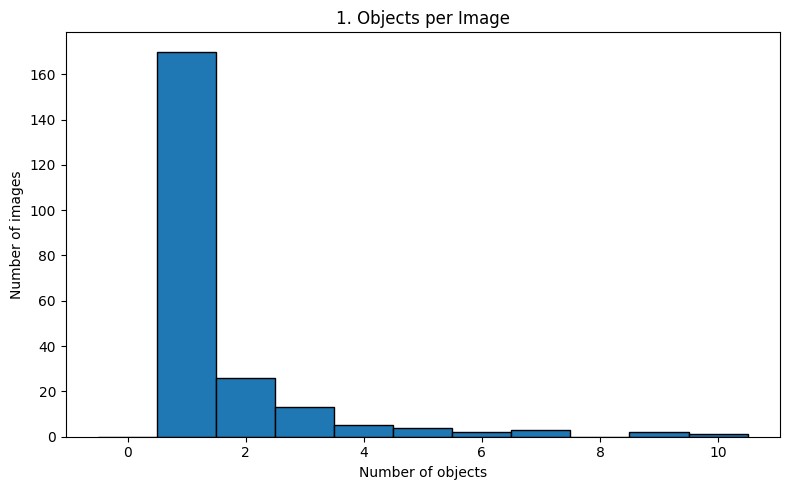

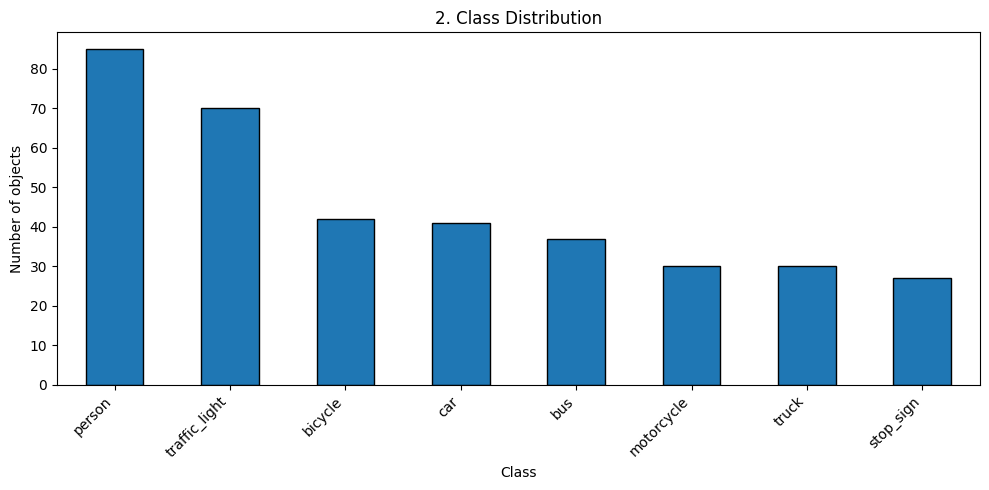

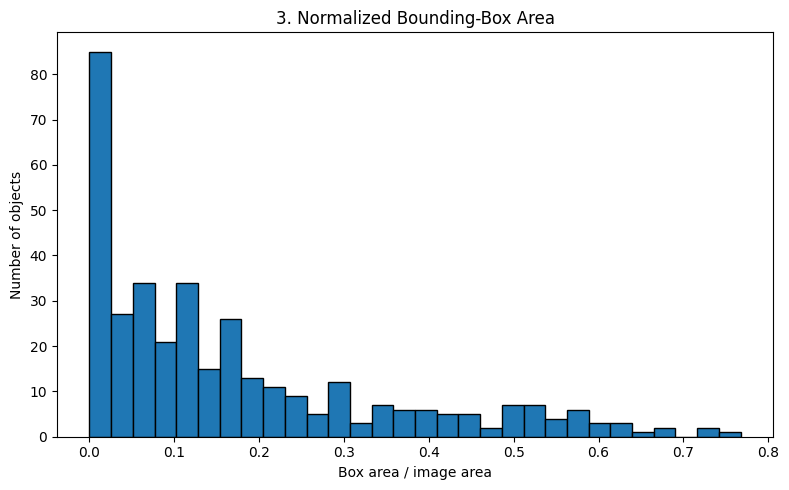

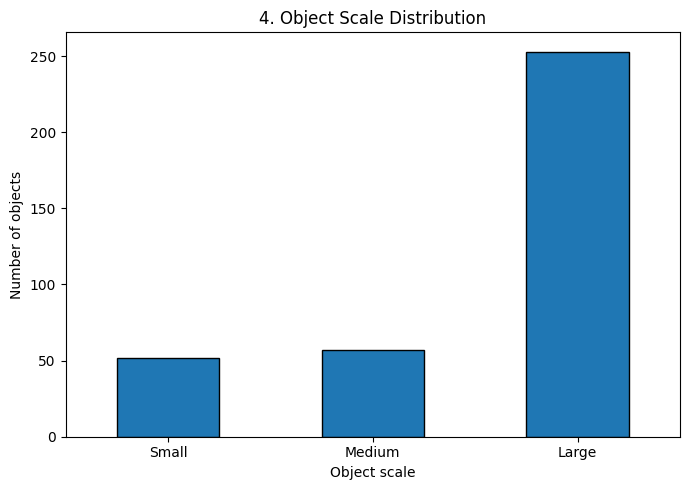

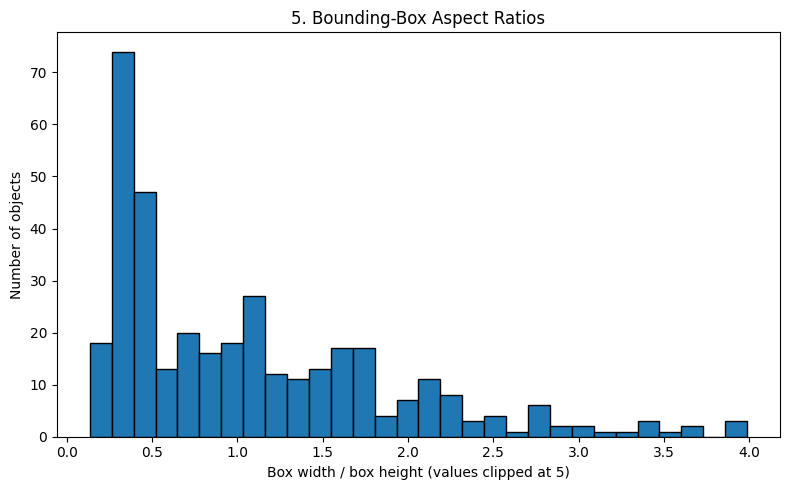

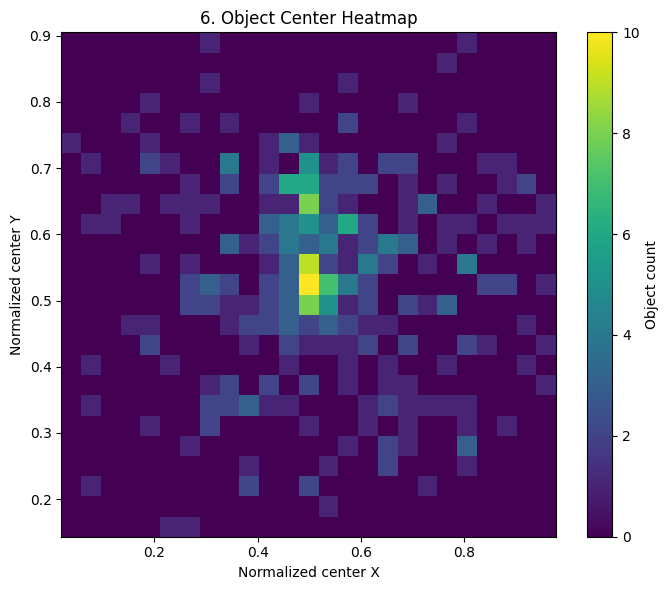

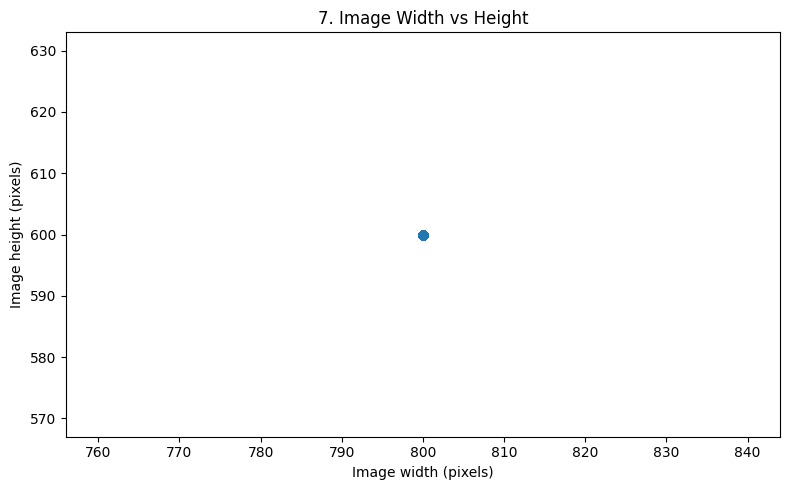

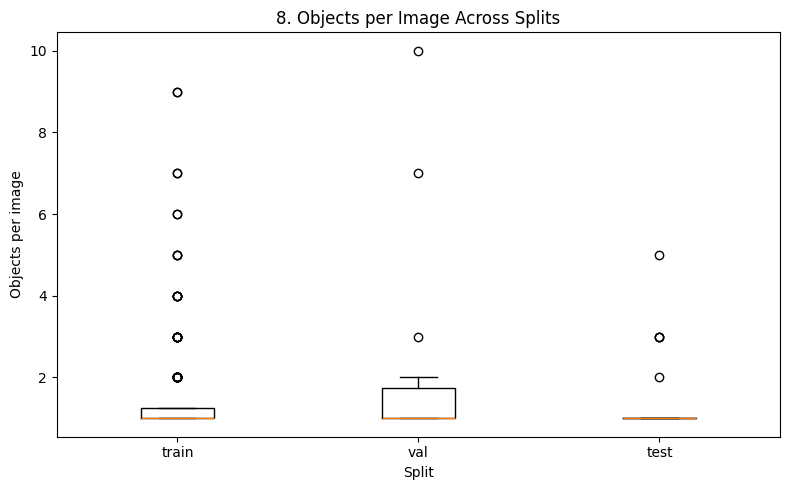

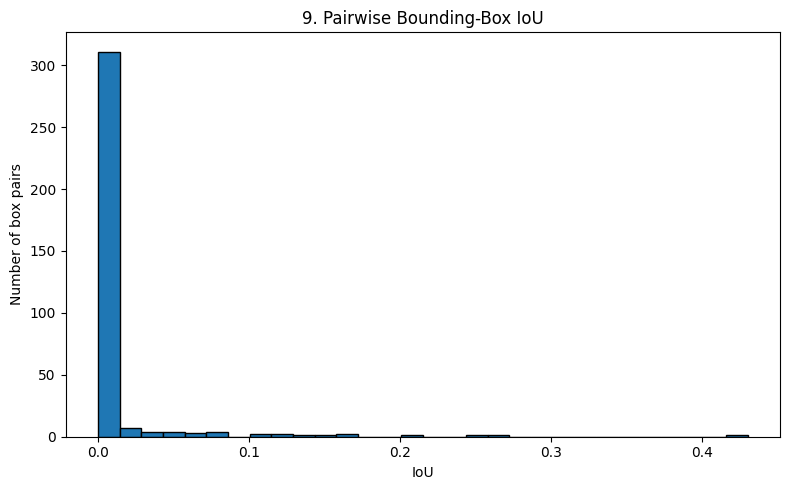

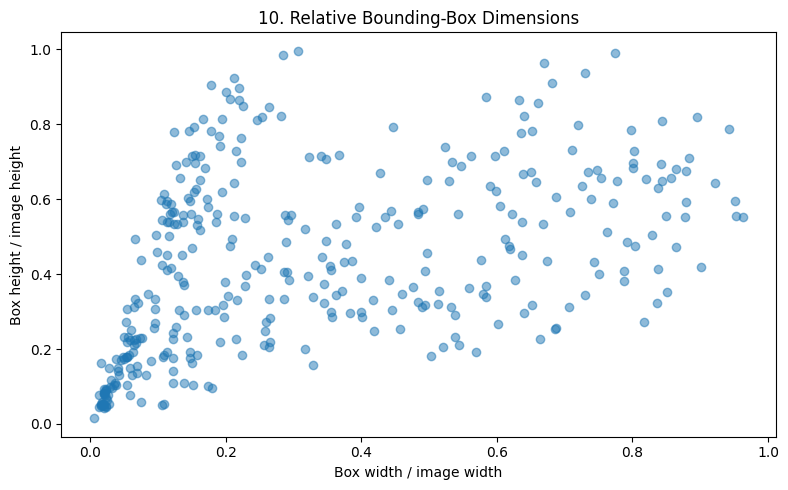


INITIAL ARCHITECTURE RECOMMENDATIONS

Backbone:
  A compact CNN backbone with standard hierarchical downsampling is a reasonable baseline.

Neck:
  Start with a lightweight FPN; compare it against a simpler single-scale neck if memory is limited.

Head:
  Start with a conventional detection head and compare per-class precision/recall before increasing complexity.

Class imbalance:
  Track per-class AP/recall. Consider class-aware sampling or a reweighted classification loss only if validation supports it.

Input geometry:
  Compare letterbox resizing against direct resizing; keep image and box coordinate transforms consistent.

Important: these recommendations are starting hypotheses, not proof that one architecture is best. Final selection requires training and validation comparisons.

PHASE 4 COMPLETED
Images analyzed       : 226
Valid objects analyzed: 362
Classes found         : 8
Charts created        : 10
Output directory      : D:\resume\13 - mini teraffic\main\result\architect

In [9]:
# ============================================================
# PHASE 4 - ARCHITECTURE SELECTION EDA
# Mini Traffic Object Detection
# 10 Numerical Indicators + 10 Charts
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm


# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(r"D:\resume\13 - mini teraffic\main")
SPLIT_DIR = PROJECT_ROOT / "result" / "splits"
OUTPUT_DIR = PROJECT_ROOT / "result" / "architecture_eda"

IMAGE_SIZE = 640
RANDOM_SEED = 42

SPLITS = ["train", "val", "test"]

if not SPLIT_DIR.exists():
    raise FileNotFoundError(
        f"Split directory not found: {SPLIT_DIR}"
    )

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {OUTPUT_DIR}\n"
        "Rename or remove the previous output before rerunning."
    )

start_time = time.perf_counter()

OUTPUT_DIR.mkdir(parents=True)
CHART_DIR = OUTPUT_DIR / "charts"
CHART_DIR.mkdir()

print("=" * 70)
print("PHASE 4 - ARCHITECTURE SELECTION EDA")
print("=" * 70)
print(f"Dataset splits : {SPLIT_DIR}")
print(f"Output         : {OUTPUT_DIR}")
print(f"Target size    : {IMAGE_SIZE} x {IMAGE_SIZE}")


# ============================================================
# 2. ANNOTATION PARSER
# ============================================================

def get_polygon_points(obj):
    """
    Extract polygon coordinates from a Supervisely-style object.
    Expected structure:
        obj["points"]["exterior"] = [[x1,y1], [x2,y2], ...]
    """
    points = obj.get("points", {})
    if not isinstance(points, dict):
        return []

    exterior = points.get("exterior", [])

    if not isinstance(exterior, list):
        return []

    valid_points = []

    for point in exterior:
        if (
            isinstance(point, (list, tuple))
            and len(point) >= 2
        ):
            try:
                x, y = float(point[0]), float(point[1])
                if np.isfinite(x) and np.isfinite(y):
                    valid_points.append((x, y))
            except (TypeError, ValueError):
                continue

    return valid_points


def extract_bbox(obj):
    """
    Return xyxy bounding box from polygon exterior points.
    """
    points = get_polygon_points(obj)

    if len(points) < 3:
        return None

    xs = [p[0] for p in points]
    ys = [p[1] for p in points]

    x1, x2 = min(xs), max(xs)
    y1, y2 = min(ys), max(ys)

    if x2 <= x1 or y2 <= y1:
        return None

    return x1, y1, x2, y2


# ============================================================
# 3. LOAD SPLIT DATA AND EXTRACT OBJECT FEATURES
# ============================================================

image_records = []
object_records = []

annotation_errors = []
unmatched_images = []
invalid_objects = []

for split_name in SPLITS:

    split_path = SPLIT_DIR / split_name
    image_dir = split_path / "images"
    annotation_dir = split_path / "annotations"

    if not image_dir.exists() or not annotation_dir.exists():
        raise FileNotFoundError(
            f"Missing images or annotations directory in {split_name}"
        )

    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file()
    )

    print(f"\nScanning {split_name}: {len(image_paths)} images")

    for image_path in tqdm(
        image_paths,
        desc=f"Reading {split_name}",
        unit="image"
    ):
        annotation_path = annotation_dir / (
            image_path.name + ".json"
        )

        if not annotation_path.exists():
            unmatched_images.append(str(image_path))
            continue

        try:
            with Image.open(image_path) as image:
                width, height = image.size
                image.load()

        except Exception as exc:
            annotation_errors.append({
                "file": str(image_path),
                "error": f"Image read error: {exc}"
            })
            continue

        try:
            with open(annotation_path, "r", encoding="utf-8") as f:
                annotation = json.load(f)

            objects = annotation.get("objects", [])

            if not isinstance(objects, list):
                raise ValueError("'objects' must be a list")

        except Exception as exc:
            annotation_errors.append({
                "file": str(annotation_path),
                "error": f"Annotation read error: {exc}"
            })
            continue

        image_object_count = 0
        image_box_areas = []

        for obj_idx, obj in enumerate(objects):

            if not isinstance(obj, dict):
                invalid_objects.append({
                    "image": image_path.name,
                    "object_index": obj_idx,
                    "reason": "Object is not a dictionary"
                })
                continue

            class_name = obj.get("classTitle")

            if not isinstance(class_name, str) or not class_name.strip():
                invalid_objects.append({
                    "image": image_path.name,
                    "object_index": obj_idx,
                    "reason": "Missing classTitle"
                })
                continue

            bbox = extract_bbox(obj)

            if bbox is None:
                invalid_objects.append({
                    "image": image_path.name,
                    "object_index": obj_idx,
                    "reason": "Invalid or insufficient polygon points"
                })
                continue

            x1, y1, x2, y2 = bbox

            # Clip coordinates to image boundaries for statistics.
            x1c = float(np.clip(x1, 0, width))
            x2c = float(np.clip(x2, 0, width))
            y1c = float(np.clip(y1, 0, height))
            y2c = float(np.clip(y2, 0, height))

            box_width = x2c - x1c
            box_height = y2c - y1c

            if box_width <= 0 or box_height <= 0:
                invalid_objects.append({
                    "image": image_path.name,
                    "object_index": obj_idx,
                    "reason": "Box outside image or zero area"
                })
                continue

            box_area = box_width * box_height
            area_ratio = box_area / (width * height)

            record = {
                "split": split_name,
                "image": image_path.name,
                "class": class_name,
                "image_width": width,
                "image_height": height,
                "box_width": box_width,
                "box_height": box_height,
                "box_area": box_area,
                "area_ratio": area_ratio,
                "width_ratio": box_width / width,
                "height_ratio": box_height / height,
                "box_aspect_ratio": box_width / box_height,
                "center_x": ((x1c + x2c) / 2) / width,
                "center_y": ((y1c + y2c) / 2) / height,
                "x1": x1c,
                "y1": y1c,
                "x2": x2c,
                "y2": y2c,
            }

            object_records.append(record)
            image_box_areas.append(area_ratio)
            image_object_count += 1

        image_records.append({
            "split": split_name,
            "image": image_path.name,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "objects": image_object_count,
            "bbox_area_sum_ratio": sum(image_box_areas),
        })


# ============================================================
# 4. DATAFRAMES
# ============================================================

images_df = pd.DataFrame(image_records)
objects_df = pd.DataFrame(object_records)

if images_df.empty:
    raise RuntimeError(
        "No usable images were read from the split directories."
    )

if objects_df.empty:
    raise RuntimeError(
        "No valid polygon bounding boxes were extracted. "
        "Check the annotation structure."
    )

# Object scale categories use normalized box area.
# These are practical EDA thresholds, not universal standards.
objects_df["size_category"] = pd.cut(
    objects_df["area_ratio"],
    bins=[-np.inf, 0.01, 0.05, np.inf],
    labels=["Small", "Medium", "Large"]
)

class_counts = objects_df["class"].value_counts().sort_values(
    ascending=False
)

objects_per_image = images_df["objects"]
box_area_ratio = objects_df["area_ratio"]
box_aspect_ratio = objects_df["box_aspect_ratio"]


# ============================================================
# 5. EXACTLY 10 NUMERICAL INDICATORS
# ============================================================

# IoU is calculated between boxes within the same image.
# This measures box overlap, not exact polygon overlap.

def calculate_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


iou_values = []

for image_name, group in tqdm(
    objects_df.groupby("image"),
    desc="Calculating box overlaps",
    unit="image"
):
    boxes = group[["x1", "y1", "x2", "y2"]].to_numpy()

    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            iou_values.append(calculate_iou(boxes[i], boxes[j]))

iou_array = np.asarray(iou_values, dtype=float)

class_probabilities = class_counts / class_counts.sum()

if len(class_counts) > 1:
    class_entropy = float(
        -(class_probabilities * np.log2(class_probabilities)).sum()
    )
else:
    class_entropy = 0.0

max_entropy = (
    float(np.log2(len(class_counts)))
    if len(class_counts) > 1 else 0.0
)

normalized_class_entropy = (
    class_entropy / max_entropy if max_entropy > 0 else 1.0
)

class_imbalance_ratio = (
    float(class_counts.max() / class_counts.min())
    if len(class_counts) > 0 else np.nan
)

size_counts = (
    objects_df["size_category"]
    .value_counts()
    .reindex(["Small", "Medium", "Large"], fill_value=0)
)

valid_aspect = box_aspect_ratio.replace(
    [np.inf, -np.inf], np.nan
).dropna()

median_image_aspect = float(images_df["aspect_ratio"].median())
median_objects = float(objects_per_image.median())
mean_objects = float(objects_per_image.mean())
small_ratio = float(size_counts["Small"] / len(objects_df))
medium_ratio = float(size_counts["Medium"] / len(objects_df))
large_ratio = float(size_counts["Large"] / len(objects_df))
median_area_ratio = float(box_area_ratio.median())
median_box_aspect = float(valid_aspect.median())
overlap_iou50_ratio = (
    float(np.mean(iou_array >= 0.50))
    if len(iou_array) else 0.0
)
overlap_iou50_ratio = float(overlap_iou50_ratio)

numerical_indicators = [
    {
        "indicator": "1. Median image aspect ratio",
        "value": median_image_aspect,
        "interpretation": (
            "Near 1.0 means square; near 1.33 means landscape. "
            "Large changes in aspect ratio may favor letterboxing."
        )
    },
    {
        "indicator": "2. Mean objects per image",
        "value": mean_objects,
        "interpretation": (
            "Higher density increases the importance of robust "
            "multi-object prediction and assignment."
        )
    },
    {
        "indicator": "3. Median objects per image",
        "value": median_objects,
        "interpretation": (
            "Represents a typical image and is less affected by "
            "images containing many objects."
        )
    },
    {
        "indicator": "4. Small-object proportion",
        "value": small_ratio,
        "interpretation": (
            "Small boxes favor higher-resolution feature maps and "
            "a multi-scale neck such as FPN/PAN."
        )
    },
    {
        "indicator": "5. Medium-object proportion",
        "value": medium_ratio,
        "interpretation": (
            "A substantial medium-object proportion supports "
            "multi-scale feature fusion."
        )
    },
    {
        "indicator": "6. Large-object proportion",
        "value": large_ratio,
        "interpretation": (
            "Large boxes can benefit from deeper semantic features."
        )
    },
    {
        "indicator": "7. Median normalized box area",
        "value": median_area_ratio,
        "interpretation": (
            "Small median area suggests preserving higher spatial "
            "resolution in the detection head."
        )
    },
    {
        "indicator": "8. Median box aspect ratio",
        "value": median_box_aspect,
        "interpretation": (
            "Extreme ratios suggest checking feature geometry and "
            "box regression behavior."
        )
    },
    {
        "indicator": "9. Fraction of box pairs with IoU >= 0.50",
        "value": overlap_iou50_ratio,
        "interpretation": (
            "Higher overlap increases the importance of careful "
            "assignment and NMS/evaluation analysis."
        )
    },
    {
        "indicator": "10. Class imbalance ratio",
        "value": class_imbalance_ratio,
        "interpretation": (
            "Large max/min ratio suggests monitoring per-class "
            "metrics and considering class-aware sampling or loss."
        )
    },
]

numerical_df = pd.DataFrame(numerical_indicators)

print("\n" + "=" * 70)
print("10 NUMERICAL INDICATORS")
print("=" * 70)

for item in numerical_indicators:
    print(f"\n{item['indicator']}: {item['value']:.5f}")
    print(f"  Interpretation: {item['interpretation']}")

print(f"\nNumber of detected classes: {len(class_counts)}")
print(f"Class entropy: {class_entropy:.4f} bits")
print(f"Normalized class entropy: {normalized_class_entropy:.4f}")


# ============================================================
# 6. EXACTLY 10 CHARTS
# ============================================================

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        CHART_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# Chart 1: Objects per image
plt.figure(figsize=(8, 5))
max_objects = int(objects_per_image.max())
bins = np.arange(-0.5, max_objects + 1.5, 1)
plt.hist(objects_per_image, bins=bins, edgecolor="black")
plt.title("1. Objects per Image")
plt.xlabel("Number of objects")
plt.ylabel("Number of images")
save_chart("01_objects_per_image.png")


# Chart 2: Class distribution
plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar", edgecolor="black")
plt.title("2. Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of objects")
plt.xticks(rotation=45, ha="right")
save_chart("02_class_distribution.png")


# Chart 3: Box area ratio
plt.figure(figsize=(8, 5))
plt.hist(box_area_ratio, bins=30, edgecolor="black")
plt.title("3. Normalized Bounding-Box Area")
plt.xlabel("Box area / image area")
plt.ylabel("Number of objects")
save_chart("03_box_area_distribution.png")


# Chart 4: Small / medium / large objects
plt.figure(figsize=(7, 5))
size_counts.plot(kind="bar", edgecolor="black")
plt.title("4. Object Scale Distribution")
plt.xlabel("Object scale")
plt.ylabel("Number of objects")
plt.xticks(rotation=0)
save_chart("04_object_scale_distribution.png")


# Chart 5: Box aspect ratios
plt.figure(figsize=(8, 5))
plt.hist(
    valid_aspect.clip(upper=5),
    bins=30,
    edgecolor="black"
)
plt.title("5. Bounding-Box Aspect Ratios")
plt.xlabel("Box width / box height (values clipped at 5)")
plt.ylabel("Number of objects")
save_chart("05_box_aspect_ratios.png")


# Chart 6: Object center distribution
plt.figure(figsize=(7, 6))
plt.hist2d(
    objects_df["center_x"],
    objects_df["center_y"],
    bins=25
)
plt.title("6. Object Center Heatmap")
plt.xlabel("Normalized center X")
plt.ylabel("Normalized center Y")
plt.colorbar(label="Object count")
save_chart("06_object_center_heatmap.png")


# Chart 7: Image dimensions
plt.figure(figsize=(8, 5))
plt.scatter(
    images_df["width"],
    images_df["height"],
    alpha=0.7
)
plt.title("7. Image Width vs Height")
plt.xlabel("Image width (pixels)")
plt.ylabel("Image height (pixels)")
save_chart("07_image_dimensions.png")


# Chart 8: Objects per image by split
plt.figure(figsize=(8, 5))
split_values = [
    images_df.loc[images_df["split"] == split, "objects"].to_numpy()
    for split in SPLITS
]
plt.boxplot(split_values, tick_labels=SPLITS)
plt.title("8. Objects per Image Across Splits")
plt.xlabel("Split")
plt.ylabel("Objects per image")
save_chart("08_split_object_counts.png")


# Chart 9: Pairwise IoU distribution
plt.figure(figsize=(8, 5))
if len(iou_array):
    plt.hist(iou_array, bins=30, edgecolor="black")
else:
    plt.text(
        0.5, 0.5,
        "No image contains more than one valid object",
        ha="center", va="center"
    )
plt.title("9. Pairwise Bounding-Box IoU")
plt.xlabel("IoU")
plt.ylabel("Number of box pairs")
save_chart("09_pairwise_iou.png")


# Chart 10: Box width and height relative to image
plt.figure(figsize=(8, 5))
plt.scatter(
    objects_df["width_ratio"],
    objects_df["height_ratio"],
    alpha=0.5
)
plt.title("10. Relative Bounding-Box Dimensions")
plt.xlabel("Box width / image width")
plt.ylabel("Box height / image height")
save_chart("10_relative_box_dimensions.png")


# ============================================================
# 7. INITIAL ARCHITECTURE RECOMMENDATION
# ============================================================

recommendations = []

# Backbone
if small_ratio >= 0.25:
    backbone_recommendation = (
        "Use a backbone that preserves useful spatial detail; "
        "avoid excessive early downsampling."
    )
else:
    backbone_recommendation = (
        "A compact CNN backbone with standard hierarchical "
        "downsampling is a reasonable baseline."
    )

recommendations.append(("Backbone", backbone_recommendation))

# Neck
if small_ratio >= 0.15 or medium_ratio >= 0.25:
    neck_recommendation = (
        "Prefer multi-scale feature fusion, starting with FPN or "
        "a lightweight PAN/FPN combination."
    )
else:
    neck_recommendation = (
        "Start with a lightweight FPN; compare it against a simpler "
        "single-scale neck if memory is limited."
    )

recommendations.append(("Neck", neck_recommendation))

# Detection head
if mean_objects >= 3 or overlap_iou50_ratio >= 0.15:
    head_recommendation = (
        "Use a multi-object detection head and carefully evaluate "
        "assignment strategy, NMS, and crowded-image performance."
    )
else:
    head_recommendation = (
        "Start with a conventional detection head and compare "
        "per-class precision/recall before increasing complexity."
    )

recommendations.append(("Head", head_recommendation))

# Class imbalance
if class_imbalance_ratio >= 3:
    imbalance_recommendation = (
        "Track per-class AP/recall. Consider class-aware sampling or "
        "a reweighted classification loss only if validation supports it."
    )
else:
    imbalance_recommendation = (
        "Begin with standard classification loss and monitor "
        "per-class performance."
    )

recommendations.append(
    ("Class imbalance", imbalance_recommendation)
)

# Image geometry
if abs(median_image_aspect - 1.0) >= 0.15:
    geometry_recommendation = (
        "Compare letterbox resizing against direct resizing; "
        "keep image and box coordinate transforms consistent."
    )
else:
    geometry_recommendation = (
        "Square resizing is geometrically reasonable, but still "
        "verify whether it distorts objects."
    )

recommendations.append(("Input geometry", geometry_recommendation))

print("\n" + "=" * 70)
print("INITIAL ARCHITECTURE RECOMMENDATIONS")
print("=" * 70)

for section, recommendation in recommendations:
    print(f"\n{section}:")
    print(f"  {recommendation}")

print(
    "\nImportant: these recommendations are starting hypotheses, "
    "not proof that one architecture is best. Final selection requires "
    "training and validation comparisons."
)


# ============================================================
# 8. SAVE REPORTS
# ============================================================

images_df.to_csv(
    OUTPUT_DIR / "image_features.csv",
    index=False,
    encoding="utf-8-sig"
)

objects_df.to_csv(
    OUTPUT_DIR / "object_features.csv",
    index=False,
    encoding="utf-8-sig"
)

numerical_df.to_csv(
    OUTPUT_DIR / "10_numerical_indicators.csv",
    index=False,
    encoding="utf-8-sig"
)

class_counts.rename("object_count").to_csv(
    OUTPUT_DIR / "class_distribution.csv",
    encoding="utf-8-sig"
)

report = {
    "phase": 4,
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "image_count": int(len(images_df)),
    "valid_object_count": int(len(objects_df)),
    "class_count": int(len(class_counts)),
    "split_image_counts": {
        str(k): int(v)
        for k, v in images_df["split"].value_counts().items()
    },
    "numerical_indicators": {
        item["indicator"]: (
            float(item["value"])
            if np.isfinite(item["value"]) else None
        )
        for item in numerical_indicators
    },
    "class_entropy_bits": float(class_entropy),
    "normalized_class_entropy": float(normalized_class_entropy),
    "pairwise_box_iou_pairs": int(len(iou_array)),
    "annotation_or_image_errors": annotation_errors,
    "unmatched_images": unmatched_images,
    "invalid_objects": invalid_objects,
    "recommendations": {
        section: recommendation
        for section, recommendation in recommendations
    },
    "chart_count": 10,
}

with open(
    OUTPUT_DIR / "phase4_architecture_eda_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(report, f, ensure_ascii=False, indent=4)

print("\n" + "=" * 70)
print("PHASE 4 COMPLETED")
print("=" * 70)
print(f"Images analyzed       : {len(images_df)}")
print(f"Valid objects analyzed: {len(objects_df)}")
print(f"Classes found         : {len(class_counts)}")
print(f"Charts created        : 10")
print(f"Output directory      : {OUTPUT_DIR}")
print(f"Elapsed time          : {time.perf_counter() - start_time:.2f} seconds")
print("\nSaved files:")
print("- image_features.csv")
print("- object_features.csv")
print("- 10_numerical_indicators.csv")
print("- class_distribution.csv")
print("- phase4_architecture_eda_report.json")
print("- charts/ (10 charts)")

In [10]:

# ============================================================
# PHASE 3.5 - APPLY PREPROCESSING TO TRAIN / VAL / TEST
# Mini Traffic Object Detection
# RGB + Letterbox 640x640 + Bounding Box/Polygon Transformation
# ============================================================

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import json
import time
import math
import shutil

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(r"D:\resume\13 - mini teraffic\main")
SOURCE_DIR = PROJECT_ROOT / "result" / "splits"
OUTPUT_DIR = PROJECT_ROOT / "result" / "preprocessing" / "processed_dataset"

TARGET_SIZE = 640
PAD_COLOR = (114, 114, 114)
IMAGE_RESAMPLE = Image.Resampling.BICUBIC

SPLITS = ["train", "val", "test"]
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

start_time = time.perf_counter()

# ============================================================
# 2. CHECK INPUTS AND OUTPUT
# ============================================================

if not SOURCE_DIR.exists():
    raise FileNotFoundError(
        f"Split directory not found: {SOURCE_DIR}"
    )

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output already exists: {OUTPUT_DIR}\n"
        "Choose another output directory or remove the old output manually."
    )

for split in SPLITS:
    image_dir = SOURCE_DIR / split / "images"
    annotation_dir = SOURCE_DIR / split / "annotations"

    if not image_dir.is_dir():
        raise FileNotFoundError(f"Missing directory: {image_dir}")

    if not annotation_dir.is_dir():
        raise FileNotFoundError(f"Missing directory: {annotation_dir}")

print("=" * 65)
print("PREPROCESSING: RGB + LETTERBOX")
print("=" * 65)
print(f"Source      : {SOURCE_DIR}")
print(f"Destination : {OUTPUT_DIR}")
print(f"Target size : {TARGET_SIZE} x {TARGET_SIZE}")


# ============================================================
# 3. LETTERBOX IMAGE AND RETURN TRANSFORM PARAMETERS
# ============================================================

def letterbox_image(image, target_size=640, pad_color=(114, 114, 114)):
    """
    Convert image to RGB, resize while preserving aspect ratio,
    and center it on a square canvas.

    Returns:
        output_image, scale, pad_left, pad_top
    """
    image = image.convert("RGB")
    original_width, original_height = image.size

    if original_width <= 0 or original_height <= 0:
        raise ValueError("Image dimensions must be positive.")

    scale = min(
        target_size / original_width,
        target_size / original_height
    )

    resized_width = max(
        1, min(target_size, int(round(original_width * scale)))
    )
    resized_height = max(
        1, min(target_size, int(round(original_height * scale)))
    )

    resized = image.resize(
        (resized_width, resized_height),
        resample=IMAGE_RESAMPLE
    )

    pad_left = (target_size - resized_width) // 2
    pad_top = (target_size - resized_height) // 2

    canvas = Image.new(
        "RGB",
        (target_size, target_size),
        color=pad_color
    )

    canvas.paste(resized, (pad_left, pad_top))

    # Use the actual resized dimensions to transform coordinates.
    scale_x = resized_width / original_width
    scale_y = resized_height / original_height

    return canvas, scale_x, scale_y, pad_left, pad_top


# ============================================================
# 4. TRANSFORM ANNOTATION COORDINATES
# ============================================================

def transform_point_list(points, scale_x, scale_y, pad_left, pad_top):
    """
    Transform a list of [x, y] points using the same geometry
    applied to the image.
    """
    if not isinstance(points, list):
        return points

    transformed = []

    for point in points:
        if (
            isinstance(point, (list, tuple))
            and len(point) >= 2
        ):
            x = float(point[0]) * scale_x + pad_left
            y = float(point[1]) * scale_y + pad_top

            if isinstance(point, tuple):
                transformed.append([x, y, *point[2:]])
            else:
                transformed.append([x, y, *point[2:]])
        else:
            # Preserve unexpected entries rather than silently
            # modifying their structure.
            transformed.append(point)

    return transformed


def transform_annotation(
    annotation,
    scale_x,
    scale_y,
    pad_left,
    pad_top,
    target_size
):
    """
    Transform Supervisely-style polygon points while preserving
    other annotation fields and class labels.
    """
    if not isinstance(annotation, dict):
        raise ValueError("Annotation root must be a JSON object.")

    objects = annotation.get("objects")

    if not isinstance(objects, list):
        raise ValueError("Annotation must contain an 'objects' list.")

    transformed_annotation = json.loads(json.dumps(annotation))

    for obj_index, obj in enumerate(transformed_annotation["objects"]):
        if not isinstance(obj, dict):
            raise ValueError(
                f"Object {obj_index} is not a JSON object."
            )

        points = obj.get("points")

        if points is None:
            continue

        if not isinstance(points, dict):
            raise ValueError(
                f"Object {obj_index}: 'points' must be an object."
            )

        for key in ("exterior", "interior"):
            if key in points:
                points[key] = transform_point_list(
                    points[key],
                    scale_x,
                    scale_y,
                    pad_left,
                    pad_top
                )

    # Update metadata when a Supervisely-style size field exists.
    if isinstance(transformed_annotation.get("size"), dict):
        transformed_annotation["size"]["width"] = target_size
        transformed_annotation["size"]["height"] = target_size

        if "depth" in transformed_annotation["size"]:
            transformed_annotation["size"]["depth"] = 3

    return transformed_annotation


# ============================================================
# 5. PREPARE OUTPUT DIRECTORIES
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

for split in SPLITS:
    (OUTPUT_DIR / split / "images").mkdir(parents=True)
    (OUTPUT_DIR / split / "annotations").mkdir(parents=True)


# ============================================================
# 6. PROCESS ALL SPLITS
# ============================================================

summary = {}
errors = []
total_processed = 0

for split in SPLITS:
    source_images = SOURCE_DIR / split / "images"
    source_annotations = SOURCE_DIR / split / "annotations"

    output_images = OUTPUT_DIR / split / "images"
    output_annotations = OUTPUT_DIR / split / "annotations"

    image_paths = sorted(
        path for path in source_images.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"\nProcessing {split.upper()}: {len(image_paths)} images")

    split_processed = 0

    for image_path in tqdm(
        image_paths,
        desc=f"Preprocessing {split}",
        unit="image"
    ):
        annotation_path = source_annotations / (image_path.name + ".json")

        if not annotation_path.is_file():
            raise FileNotFoundError(
                f"Annotation missing for image: {image_path.name}"
            )

        try:
            # Read and preprocess image.
            with Image.open(image_path) as image:
                original_width, original_height = image.size

                processed_image, scale_x, scale_y, pad_left, pad_top = (
                    letterbox_image(
                        image,
                        target_size=TARGET_SIZE,
                        pad_color=PAD_COLOR
                    )
                )

            # Read and transform annotation.
            with open(annotation_path, "r", encoding="utf-8") as f:
                annotation = json.load(f)

            transformed_annotation = transform_annotation(
                annotation=annotation,
                scale_x=scale_x,
                scale_y=scale_y,
                pad_left=pad_left,
                pad_top=pad_top,
                target_size=TARGET_SIZE
            )

            # Save processed image using its original filename.
            output_image_path = output_images / image_path.name

            processed_image.save(
                output_image_path,
                format="JPEG" if image_path.suffix.lower() in {
                    ".jpg", ".jpeg"
                } else None
            ) if image_path.suffix.lower() in {".jpg", ".jpeg"} else (
                processed_image.save(output_image_path, format="PNG")
            )

            # Preserve the annotation filename convention.
            output_annotation_path = (
                output_annotations / annotation_path.name
            )

            with open(
                output_annotation_path,
                "w",
                encoding="utf-8"
            ) as f:
                json.dump(
                    transformed_annotation,
                    f,
                    ensure_ascii=False,
                    indent=2
                )

            # Basic output size check.
            with Image.open(output_image_path) as saved_image:
                if saved_image.size != (TARGET_SIZE, TARGET_SIZE):
                    raise RuntimeError(
                        f"Incorrect output dimensions: {image_path.name}"
                    )

                if saved_image.mode != "RGB":
                    raise RuntimeError(
                        f"Output is not RGB: {image_path.name}"
                    )

            split_processed += 1
            total_processed += 1

        except Exception as exc:
            errors.append({
                "split": split,
                "image": image_path.name,
                "error": str(exc)
            })

            raise RuntimeError(
                f"Preprocessing failed for {split}/{image_path.name}: {exc}\n"
                f"Partial output remains at: {OUTPUT_DIR}"
            ) from exc

    summary[split] = {
        "input_images": len(image_paths),
        "processed_images": split_processed
    }


# ============================================================
# 7. FINAL SUMMARY
# ============================================================

elapsed = time.perf_counter() - start_time

print("\n" + "=" * 65)
print("PREPROCESSING COMPLETED")
print("=" * 65)

for split in SPLITS:
    print(
        f"{split.upper():5s}: "
        f"{summary[split]['processed_images']} / "
        f"{summary[split]['input_images']} images"
    )

print(f"\nTotal processed: {total_processed}")
print(f"Output size    : {TARGET_SIZE} x {TARGET_SIZE}")
print("Color mode     : RGB")
print("Resize method  : Letterbox")
print("CLAHE          : Not applied")
print("Denoising      : Not applied")
print("Brightness fix : Not applied")
print("Pixel scaling  : Not applied to saved images")
print(f"Elapsed time   : {elapsed:.2f} seconds")
print(f"Output         : {OUTPUT_DIR}")
print("\nOriginal split files were not modified.")
print("Pixel values will be converted to [0, 1] when loaded for training.")

PREPROCESSING: RGB + LETTERBOX
Source      : D:\resume\13 - mini teraffic\main\result\splits
Destination : D:\resume\13 - mini teraffic\main\result\preprocessing\processed_dataset
Target size : 640 x 640

Processing TRAIN: 180 images


Preprocessing train:   0%|          | 0/180 [00:00<?, ?image/s]


Processing VAL: 22 images


Preprocessing val:   0%|          | 0/22 [00:00<?, ?image/s]


Processing TEST: 24 images


Preprocessing test:   0%|          | 0/24 [00:00<?, ?image/s]


PREPROCESSING COMPLETED
TRAIN: 180 / 180 images
VAL  : 22 / 22 images
TEST : 24 / 24 images

Total processed: 226
Output size    : 640 x 640
Color mode     : RGB
Resize method  : Letterbox
CLAHE          : Not applied
Denoising      : Not applied
Brightness fix : Not applied
Pixel scaling  : Not applied to saved images
Elapsed time   : 12.35 seconds
Output         : D:\resume\13 - mini teraffic\main\result\preprocessing\processed_dataset

Original split files were not modified.
Pixel values will be converted to [0, 1] when loaded for training.


In [11]:

# ============================================================
# PHASE 5 - YOLOv8n MODEL CONSTRUCTION
# Mini Traffic Object Detection
# PyTorch + Pretrained COCO Weights
# ============================================================

from pathlib import Path
from datetime import datetime
from collections import Counter
import json
import time

import torch
import yaml
from tqdm.auto import tqdm
from ultralytics import YOLO
from ultralytics.utils.loss import v8DetectionLoss
from ultralytics.nn.tasks import DetectionModel


# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(r"D:\resume\13 - mini teraffic\main")

DATASET_DIR = (
    PROJECT_ROOT
    / "result"
    / "preprocessing"
    / "processed_dataset"
)

PHASE5_DIR = PROJECT_ROOT / "result" / "model"

IMAGE_SIZE = 640
BATCH_SIZE = 4
NUM_CLASSES_EXPECTED = 8
MODEL_NAME = "yolov8n"
PRETRAINED_WEIGHTS = "yolov8n.pt"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

start_time = time.perf_counter()

print("=" * 70)
print("PHASE 5 - YOLOv8n MODEL CONSTRUCTION")
print("=" * 70)
print(f"Device       : {DEVICE}")
print(f"Dataset      : {DATASET_DIR}")
print(f"Output       : {PHASE5_DIR}")
print(f"Input size   : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size   : {BATCH_SIZE}")


# ============================================================
# 2. CHECK DATASET
# ============================================================

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Preprocessed dataset not found: {DATASET_DIR}"
    )

if PHASE5_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {PHASE5_DIR}\n"
        "Choose another output directory or remove the old one manually."
    )

for split in ("train", "val", "test"):
    split_images = DATASET_DIR / split / "images"
    split_annotations = DATASET_DIR / split / "annotations"

    if not split_images.is_dir():
        raise FileNotFoundError(
            f"Missing directory: {split_images}"
        )

    if not split_annotations.is_dir():
        raise FileNotFoundError(
            f"Missing directory: {split_annotations}"
        )


# ============================================================
# 3. COLLECT CLASS NAMES FROM ANNOTATIONS
# ============================================================

class_names_found = set()
annotation_count = 0

annotation_paths = []

for split in ("train", "val", "test"):
    annotation_paths.extend(
        sorted((DATASET_DIR / split / "annotations").glob("*.json"))
    )

for annotation_path in tqdm(
    annotation_paths,
    desc="Reading class names",
    unit="file"
):
    with open(annotation_path, "r", encoding="utf-8") as f:
        annotation = json.load(f)

    objects = annotation.get("objects", [])

    if not isinstance(objects, list):
        raise ValueError(
            f"Invalid objects list: {annotation_path}"
        )

    for obj in objects:
        if not isinstance(obj, dict):
            continue

        class_name = obj.get("classTitle")

        if isinstance(class_name, str) and class_name.strip():
            class_names_found.add(class_name.strip())

    annotation_count += 1

CLASS_NAMES = sorted(class_names_found)

if len(CLASS_NAMES) != NUM_CLASSES_EXPECTED:
    raise ValueError(
        f"Expected {NUM_CLASSES_EXPECTED} classes, "
        f"but found {len(CLASS_NAMES)}: {CLASS_NAMES}"
    )

NUM_CLASSES = len(CLASS_NAMES)

print(f"\nAnnotations scanned: {annotation_count}")
print(f"Number of classes  : {NUM_CLASSES}")

for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"  {class_id}: {class_name}")


# ============================================================
# 4. CREATE OUTPUT DIRECTORY AND SAVE CLASS MAP
# ============================================================

PHASE5_DIR.mkdir(parents=True, exist_ok=False)

with open(
    PHASE5_DIR / "class_map.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "nc": NUM_CLASSES,
            "names": {
                str(index): name
                for index, name in enumerate(CLASS_NAMES)
            },
        },
        f,
        ensure_ascii=False,
        indent=2
    )


# ============================================================
# 5. CREATE YOLOv8 CONFIGURATION WITH 8 CLASSES
# ============================================================

import ultralytics

ultralytics_dir = Path(ultralytics.__file__).resolve().parent

candidate_yaml_paths = [
    ultralytics_dir / "cfg" / "models" / "v8" / "yolov8.yaml",
    ultralytics_dir / "cfg" / "models" / "v8" / "yolov8n.yaml",
]

base_yaml_path = next(
    (path for path in candidate_yaml_paths if path.exists()),
    None
)

if base_yaml_path is None:
    raise FileNotFoundError(
        "Could not locate the installed YOLOv8 model YAML."
    )

with open(base_yaml_path, "r", encoding="utf-8") as f:
    model_yaml = yaml.safe_load(f)

model_yaml["nc"] = NUM_CLASSES

custom_yaml_path = PHASE5_DIR / "yolov8n_minitraffic.yaml"

with open(custom_yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        model_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print(f"\nModel configuration saved: {custom_yaml_path}")


# ============================================================
# 6. BUILD MODEL AND LOAD PRETRAINED WEIGHTS
# ============================================================

print("\nBuilding YOLOv8n architecture...")

# Construct the official YOLOv8 model with the custom class count.
yolo = YOLO(str(custom_yaml_path), task="detect")

if not isinstance(yolo.model, DetectionModel):
    raise TypeError(
        "The constructed model is not an Ultralytics DetectionModel."
    )

print("Architecture created successfully.")

print(f"\nLoading pretrained weights: {PRETRAINED_WEIGHTS}")

# Transfer compatible weights from the official COCO checkpoint.
# The detection output layers for 8 classes are initialized for this dataset.
yolo.load(PRETRAINED_WEIGHTS)

model = yolo.model
model = model.to(DEVICE)

print("Pretrained weight transfer completed.")


# ============================================================
# 7. VERIFY MODEL OUTPUT AND DETECTION SCALES
# ============================================================

model.eval()

dummy_input = torch.zeros(
    1, 3, IMAGE_SIZE, IMAGE_SIZE,
    device=DEVICE
)

with torch.no_grad():
    raw_output = model(dummy_input)

print("\nForward-pass test completed.")

# During evaluation, Ultralytics returns decoded predictions and
# raw head features. During training, raw head features are returned.
if isinstance(raw_output, tuple):
    print(f"Output type: tuple with {len(raw_output)} elements")
else:
    print(f"Output type: {type(raw_output).__name__}")

# Inspect the detection head.
detection_head = model.model[-1]

print(f"\nDetection head type : {type(detection_head).__name__}")
print(f"Number of classes   : {detection_head.nc}")
print(f"Number of scales    : {len(detection_head.stride)}")
print(f"Strides             : {detection_head.stride.tolist()}")

if detection_head.nc != NUM_CLASSES:
    raise RuntimeError(
        f"Detection head has {detection_head.nc} classes, "
        f"expected {NUM_CLASSES}."
    )

expected_strides = [8.0, 16.0, 32.0]
actual_strides = detection_head.stride.detach().cpu().tolist()

if actual_strides != expected_strides:
    raise RuntimeError(
        f"Unexpected detection strides: {actual_strides}"
    )


# ============================================================
# 8. INITIALIZE STANDARD YOLOv8 TRAINING LOSS
# ============================================================

# v8DetectionLoss uses the official implementation of:
# - Task-Aligned Assigner (TAL)
# - BCEWithLogits classification loss
# - CIoU bounding-box loss
# - Distribution Focal Loss (DFL)

criterion = v8DetectionLoss(model)

print("\nYOLOv8 loss criterion initialized.")
print("Components are provided by the installed Ultralytics version:")
print("  - Task-Aligned Assigner (TAL)")
print("  - BCEWithLogits classification loss")
print("  - CIoU bounding-box loss")
print("  - Distribution Focal Loss (DFL)")


# ============================================================
# 9. COUNT PARAMETERS
# ============================================================

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nModel statistics:")
print(f"Total parameters     : {total_parameters:,}")
print(f"Trainable parameters : {trainable_parameters:,}")
print(f"Model size (FP32)    : {total_parameters * 4 / (1024 ** 2):.2f} MiB")


# ============================================================
# 10. SAVE MODEL CHECKPOINT AND CONFIGURATION
# ============================================================

checkpoint_path = PHASE5_DIR / "yolov8n_minitraffic_initial.pt"

# Save the initialized PyTorch model for reproducibility.
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "model_yaml": model_yaml,
        "class_names": CLASS_NAMES,
        "num_classes": NUM_CLASSES,
        "image_size": IMAGE_SIZE,
        "model_name": MODEL_NAME,
        "pretrained_weights": PRETRAINED_WEIGHTS,
        "created_at": datetime.now().isoformat(timespec="seconds"),
    },
    checkpoint_path
)

summary = {
    "phase": 5,
    "model": MODEL_NAME,
    "implementation": "Ultralytics PyTorch DetectionModel",
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "input_channels": 3,
    "expected_strides": expected_strides,
    "total_parameters": int(total_parameters),
    "trainable_parameters": int(trainable_parameters),
    "pretrained_weights": PRETRAINED_WEIGHTS,
    "loss": [
        "Task-Aligned Assigner",
        "BCEWithLogits",
        "CIoU",
        "DFL",
    ],
    "checkpoint": str(checkpoint_path),
    "model_yaml": str(custom_yaml_path),
    "created_at": datetime.now().isoformat(timespec="seconds"),
}

with open(
    PHASE5_DIR / "phase5_model_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)


# ============================================================
# 11. FINAL SUMMARY
# ============================================================

elapsed = time.perf_counter() - start_time

print("\n" + "=" * 70)
print("PHASE 5 COMPLETED")
print("=" * 70)
print(f"Model              : {MODEL_NAME}")
print(f"Classes            : {NUM_CLASSES}")
print(f"Parameters          : {total_parameters:,}")
print(f"Device              : {DEVICE}")
print(f"Pretrained weights  : {PRETRAINED_WEIGHTS}")
print(f"Checkpoint          : {checkpoint_path}")
print(f"Configuration       : {custom_yaml_path}")
print(f"Summary             : {PHASE5_DIR / 'phase5_model_summary.json'}")
print(f"Elapsed time        : {elapsed:.2f} seconds")
print("\nNo model training was performed in Phase 5.")

PHASE 5 - YOLOv8n MODEL CONSTRUCTION
Device       : cuda
Dataset      : D:\resume\13 - mini teraffic\main\result\preprocessing\processed_dataset
Output       : D:\resume\13 - mini teraffic\main\result\model
Input size   : 640 x 640
Batch size   : 4


Reading class names:   0%|          | 0/226 [00:00<?, ?file/s]


Annotations scanned: 226
Number of classes  : 8
  0: bicycle
  1: bus
  2: car
  3: motorcycle
  4: person
  5: stop_sign
  6: traffic_light
  7: truck

Model configuration saved: D:\resume\13 - mini teraffic\main\result\model\yolov8n_minitraffic.yaml

Building YOLOv8n architecture...
Architecture created successfully.

Loading pretrained weights: yolov8n.pt
Transferred 319/355 items from pretrained weights
Pretrained weight transfer completed.

Forward-pass test completed.
Output type: tuple with 2 elements

Detection head type : Detect
Number of classes   : 8
Number of scales    : 3
Strides             : [8.0, 16.0, 32.0]

YOLOv8 loss criterion initialized.
Components are provided by the installed Ultralytics version:
  - Task-Aligned Assigner (TAL)
  - BCEWithLogits classification loss
  - CIoU bounding-box loss
  - Distribution Focal Loss (DFL)

Model statistics:
Total parameters     : 3,012,408
Trainable parameters : 3,012,392
Model size (FP32)    : 11.49 MiB

PHASE 5 COMPLETED
M

In [2]:
# ============================================================
# PHASE 6 - ROBUST YOLOv8n TRAINING WITH ADVANCED SCHEDULING
# Mini Traffic Object Detection
#
# Features:
#   1. Automatic validation/reuse of an existing YOLO dataset
#   2. Safe creation of a new dataset if the existing one is invalid
#   3. Polygon-to-YOLO bounding-box conversion
#   4. Exact class mapping from Phase 5
#   5. Pretrained YOLOv8n initialization
#   6. Live Ultralytics training and validation progress
#   7. Batch-level CSV logging
#   8. Epoch-level metrics and best checkpoint reporting
#   9. Custom ReduceLROnPlateau callback via on_fit_epoch_end
#  10. Native EarlyStopping via patience argument
#  11. Unique training run directory without deleting previous runs
#
# Jupyter notebook cell: no main() function
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import csv
import shutil
import time
import math

import numpy as np
import pandas as pd
import torch
import yaml

from PIL import Image
from tqdm.auto import tqdm
from ultralytics import YOLO


# ============================================================
# 2. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(r"D:\resume\13 - mini teraffic\main")

RESULT_DIR = PROJECT_ROOT / "result"
PROCESSED_DIR = RESULT_DIR / "preprocessing" / "processed_dataset"
PHASE5_DIR = RESULT_DIR / "model"

MODEL_YAML = PHASE5_DIR / "yolov8n_minitraffic.yaml"
CLASS_MAP_PATH = PHASE5_DIR / "class_map.json"
YOLO_DATASET_BASE = RESULT_DIR / "yolo_dataset"
TRAINING_DIR = RESULT_DIR / "training"

PRETRAINED_WEIGHTS = "yolov8n.pt"

IMAGE_SIZE = 640
BATCH_SIZE = 4
EPOCHS = 50

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# Early Stopping & ReduceLROnPlateau Settings
EARLY_STOPPING_PATIENCE = 12       # Ultralytics native early stopping patience (epochs)
PLATEAU_PATIENCE = 4              # Epochs to wait before reducing LR
PLATEAU_FACTOR = 0.5              # Multiplier for LR decay (new_lr = lr * factor)
PLATEAU_MIN_LR = 1e-6             # Lower bound for learning rate
PLATEAU_MIN_DELTA = 1e-4          # Minimum threshold to qualify as improvement

NUM_WORKERS = 0
USE_AMP = True
SEED = 42

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}

SPLITS = ("train", "val", "test")
NUM_EXPECTED_CLASSES = 8

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Timestamp prevents accidental reuse of an earlier run
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_NAME = f"phase6_yolov8n_{RUN_TIMESTAMP}"
RUN_DIR = TRAINING_DIR / RUN_NAME

# Independent batch log state
BATCH_LOG_STATE = {
    "file": None,
    "writer": None,
    "run_dir": None,
    "batch_index": 0,
}

# State management for ReduceLROnPlateau
PLATEAU_STATE = {
    "best_fitness": -float("inf"),
    "wait_epochs": 0,
    "current_lr": LEARNING_RATE,
}

PHASE6_STARTED_AT = datetime.now().isoformat(timespec="seconds")


# ============================================================
# 3. INITIAL REPORT
# ============================================================

print("=" * 80)
print("PHASE 6 - ROBUST YOLOv8n TRAINING (WITH LR PLATEAU & EARLY STOPPING)")
print("=" * 80)

print(f"Project root            : {PROJECT_ROOT}")
print(f"Processed data          : {PROCESSED_DIR}")
print(f"Phase 5 model           : {MODEL_YAML}")
print(f"Class mapping           : {CLASS_MAP_PATH}")
print(f"Device                  : {DEVICE}")
print(f"Image size              : {IMAGE_SIZE}")
print(f"Batch size              : {BATCH_SIZE}")
print(f"Epochs                  : {EPOCHS}")
print(f"Initial LR (lr0)        : {LEARNING_RATE}")
print(f"ReduceLR Patience       : {PLATEAU_PATIENCE} epochs (Factor: {PLATEAU_FACTOR})")
print(f"Early Stopping Patience : {EARLY_STOPPING_PATIENCE} epochs")
print(f"Weight decay            : {WEIGHT_DECAY}")
print(f"Workers                 : {NUM_WORKERS}")
print(f"AMP requested           : {USE_AMP}")
print(f"Run name                : {RUN_NAME}")


# ============================================================
# 4. CHECK ENVIRONMENT AND INPUT PATHS
# ============================================================

required_paths = [
    PROJECT_ROOT,
    PROCESSED_DIR,
    PHASE5_DIR,
    MODEL_YAML,
    CLASS_MAP_PATH,
]

for required_path in required_paths:
    if not required_path.exists():
        raise FileNotFoundError(f"Required path does not exist:\n{required_path}")

for split in SPLITS:
    split_images = PROCESSED_DIR / split / "images"
    split_annotations = PROCESSED_DIR / split / "annotations"

    if not split_images.is_dir():
        raise FileNotFoundError(f"Image directory is missing:\n{split_images}")

    if not split_annotations.is_dir():
        raise FileNotFoundError(f"Annotation directory is missing:\n{split_annotations}")

TRAINING_DIR.mkdir(parents=True, exist_ok=True)

if RUN_DIR.exists():
    raise FileExistsError(
        f"Training run already exists:\n{RUN_DIR}\n"
        "Run the cell again to generate a fresh timestamp."
    )

if torch.cuda.is_available():
    print("\nGPU information:")
    print(f"GPU name         : {torch.cuda.get_device_name(0)}")
    print(f"GPU memory       : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GiB")
    if BATCH_SIZE > 4:
        print("WARNING: The selected batch size may require more GPU memory.")
else:
    print("\nWARNING: CUDA is unavailable. Training will run on the CPU.")


# ============================================================
# 5. LOAD CLASS MAPPING FROM PHASE 5
# ============================================================

with open(CLASS_MAP_PATH, "r", encoding="utf-8") as file:
    class_map_data = json.load(file)


def normalize_class_mapping(data):
    if "names" not in data:
        raise ValueError("The Phase 5 class mapping has no 'names' field.")

    names_data = data["names"]

    if isinstance(names_data, list):
        class_names = [str(name) for name in names_data]
    elif isinstance(names_data, dict):
        number_of_classes = int(data.get("nc", len(names_data)))
        class_names = []
        for class_id in range(number_of_classes):
            key = str(class_id)
            if key not in names_data:
                raise ValueError(f"Missing class ID {class_id} in {CLASS_MAP_PATH}")
            class_names.append(str(names_data[key]))
    else:
        raise TypeError("Unsupported class mapping format. The 'names' field must be a list or dict.")

    if len(class_names) != len(set(class_names)):
        raise ValueError("Duplicate class names were found in class_map.json.")

    declared_nc = int(data.get("nc", len(class_names)))
    if declared_nc != len(class_names):
        raise ValueError(f"Declared nc={declared_nc}, but {len(class_names)} class names were found.")

    return class_names


CLASS_NAMES = normalize_class_mapping(class_map_data)
NUM_CLASSES = len(CLASS_NAMES)

if NUM_CLASSES != NUM_EXPECTED_CLASSES:
    raise ValueError(
        f"Expected {NUM_EXPECTED_CLASSES} classes, but found {NUM_CLASSES}.\n"
        f"Classes: {CLASS_NAMES}"
    )

CLASS_TO_ID = {name: class_id for class_id, name in enumerate(CLASS_NAMES)}

print("\nClass mapping loaded successfully:")
for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"  {class_id:2d} -> {class_name}")


# ============================================================
# 6. POLYGON TO BOUNDING BOX CONVERSION
# ============================================================

def polygon_to_bbox(points, image_width, image_height):
    if not isinstance(points, list) or len(points) < 3:
        return None

    parsed_points = []
    for point in points:
        try:
            if isinstance(point, dict):
                x = float(point["x"])
                y = float(point["y"])
            elif isinstance(point, (list, tuple)) and len(point) >= 2:
                x = float(point[0])
                y = float(point[1])
            else:
                continue

            if np.isfinite(x) and np.isfinite(y):
                parsed_points.append((x, y))
        except (TypeError, ValueError, KeyError, IndexError):
            continue

    if len(parsed_points) < 3:
        return None

    xs = [point[0] for point in parsed_points]
    ys = [point[1] for point in parsed_points]

    x_min = float(np.clip(min(xs), 0, image_width))
    y_min = float(np.clip(min(ys), 0, image_height))
    x_max = float(np.clip(max(xs), 0, image_width))
    y_max = float(np.clip(max(ys), 0, image_height))

    if x_max <= x_min or y_max <= y_min:
        return None

    return (x_min, y_min, x_max, y_max)


def bbox_to_yolo_line(class_id, bbox, image_width, image_height):
    x_min, y_min, x_max, y_max = bbox

    x_center = ((x_min + x_max) / 2.0) / image_width
    y_center = ((y_min + y_max) / 2.0) / image_height
    box_width = (x_max - x_min) / image_width
    box_height = (y_max - y_min) / image_height

    values = [x_center, y_center, box_width, box_height]
    if not all(np.isfinite(v) for v in values):
        return None

    if not (0.0 <= x_center <= 1.0 and 0.0 <= y_center <= 1.0 and 0.0 < box_width <= 1.0 and 0.0 < box_height <= 1.0):
        return None

    return f"{int(class_id)} {x_center:.8f} {y_center:.8f} {box_width:.8f} {box_height:.8f}"


# ============================================================
# 7. VALIDATE AN EXISTING YOLO DATASET
# ============================================================

def validate_existing_yolo_dataset(dataset_dir):
    if not dataset_dir.is_dir():
        return False, "Dataset directory does not exist.", {}

    data_yaml_path = dataset_dir / "data.yaml"
    if not data_yaml_path.is_file():
        return False, "data.yaml is missing.", {}

    try:
        with open(data_yaml_path, "r", encoding="utf-8") as file:
            config = yaml.safe_load(file)
    except Exception as error:
        return False, f"Cannot read data.yaml: {error}", {}

    if not isinstance(config, dict):
        return False, "data.yaml does not contain a valid mapping.", {}

    if int(config.get("nc", -1)) != NUM_CLASSES:
        return False, "Dataset class count does not match Phase 5.", {}

    configured_names = config.get("names")
    if isinstance(configured_names, dict):
        try:
            configured_names = [str(configured_names[str(i)]) for i in range(NUM_CLASSES)]
        except KeyError:
            return False, "data.yaml has missing class IDs.", {}
    elif isinstance(configured_names, list):
        configured_names = [str(name) for name in configured_names]
    else:
        return False, "data.yaml contains an invalid names field.", {}

    if configured_names != CLASS_NAMES:
        return False, "Dataset class names/order differs from Phase 5.", {}

    statistics = {}

    for split in SPLITS:
        images_dir = dataset_dir / split / "images"
        labels_dir = dataset_dir / split / "labels"

        if not images_dir.is_dir():
            return False, f"{split}: images directory is missing.", {}

        if not labels_dir.is_dir():
            return False, f"{split}: labels directory is missing.", {}

        image_paths = sorted(
            path for path in images_dir.iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )
        label_paths = list(labels_dir.glob("*.txt"))

        image_stems = [path.stem for path in image_paths]
        if len(image_stems) != len(set(image_stems)):
            return False, f"{split}: duplicate image stems detected.", {}

        label_stems = {path.stem for path in label_paths}
        if not image_paths:
            return False, f"{split}: no images found.", {}

        if set(image_stems) != label_stems:
            return False, f"{split}: image/label pairs do not match.", {}

        valid_objects = 0
        invalid_label_lines = 0

        for label_path in label_paths:
            try:
                lines = label_path.read_text(encoding="utf-8").splitlines()
            except OSError:
                return False, f"Cannot read label: {label_path}", {}

            for line in lines:
                parts = line.strip().split()
                if len(parts) != 5:
                    invalid_label_lines += 1
                    continue

                try:
                    class_id = int(parts[0])
                    box_values = [float(v) for v in parts[1:]]
                except ValueError:
                    invalid_label_lines += 1
                    continue

                if not (
                    0 <= class_id < NUM_CLASSES
                    and all(math.isfinite(v) for v in box_values)
                    and 0.0 <= box_values[0] <= 1.0
                    and 0.0 <= box_values[1] <= 1.0
                    and 0.0 < box_values[2] <= 1.0
                    and 0.0 < box_values[3] <= 1.0
                ):
                    invalid_label_lines += 1
                    continue

                valid_objects += 1

        if invalid_label_lines > 0:
            return False, f"{split}: {invalid_label_lines} invalid label lines.", {}

        statistics[split] = {
            "images": len(image_paths),
            "label_files": len(label_paths),
            "valid_objects": valid_objects,
            "skipped_objects": 0,
            "empty_label_files": sum(1 for path in label_paths if path.stat().st_size == 0),
        }

    if statistics["train"]["valid_objects"] == 0 or statistics["val"]["valid_objects"] == 0:
        return False, "Train or validation split contains no valid objects.", {}

    return True, "Existing dataset passed structural and label checks.", statistics


# ============================================================
# 8. SELECT A SAFE DATASET OUTPUT DIRECTORY
# ============================================================

existing_dataset_is_valid = False
dataset_statistics = {}

if YOLO_DATASET_BASE.exists():
    existing_dataset_is_valid, dataset_message, dataset_statistics = validate_existing_yolo_dataset(YOLO_DATASET_BASE)
    print("\nExisting dataset check:")
    print(f"Path   : {YOLO_DATASET_BASE}")
    print(f"Valid  : {existing_dataset_is_valid}")
    print(f"Reason : {dataset_message}")

    if existing_dataset_is_valid:
        YOLO_DATASET_DIR = YOLO_DATASET_BASE
        print("\nThe existing YOLO dataset will be reused.")
    else:
        suffix = datetime.now().strftime("%Y%m%d_%H%M%S")
        YOLO_DATASET_DIR = RESULT_DIR / f"yolo_dataset_rebuild_{suffix}"
        print(f"\nThe existing dataset will be preserved. Creating at: {YOLO_DATASET_DIR}")
else:
    YOLO_DATASET_DIR = YOLO_DATASET_BASE
    print("\nNo previous YOLO dataset found. A new dataset will be created.")


# ============================================================
# 9. BUILD A YOLO DATASET WHEN NECESSARY
# ============================================================

unknown_classes = set()

if not existing_dataset_is_valid:
    if YOLO_DATASET_DIR.exists():
        raise FileExistsError(f"Refusing to overwrite dataset directory:\n{YOLO_DATASET_DIR}")

    YOLO_DATASET_DIR.mkdir(parents=True, exist_ok=False)
    dataset_statistics = {}

    for split in SPLITS:
        source_images_dir = PROCESSED_DIR / split / "images"
        source_annotations_dir = PROCESSED_DIR / split / "annotations"

        output_images_dir = YOLO_DATASET_DIR / split / "images"
        output_labels_dir = YOLO_DATASET_DIR / split / "labels"

        output_images_dir.mkdir(parents=True, exist_ok=False)
        output_labels_dir.mkdir(parents=True, exist_ok=False)

        image_paths = sorted(
            path for path in source_images_dir.iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )

        if not image_paths:
            raise RuntimeError(f"No images found in:\n{source_images_dir}")

        source_stems = [p.stem for p in image_paths]
        if len(source_stems) != len(set(source_stems)):
            raise ValueError(f"Duplicate image stems in {split}.")

        converted_images = 0
        converted_objects = 0
        skipped_objects = 0
        empty_labels = 0

        print(f"\nConverting {split}: {len(image_paths)} images")

        for image_path in tqdm(image_paths, desc=f"Preparing {split}", unit="image"):
            annotation_path = source_annotations_dir / f"{image_path.name}.json"
            if not annotation_path.is_file():
                raise FileNotFoundError(f"Annotation missing for:\n{image_path}")

            try:
                with open(annotation_path, "r", encoding="utf-8") as file:
                    annotation = json.load(file)
            except Exception as error:
                raise RuntimeError(f"Cannot parse annotation:\n{annotation_path}") from error

            with Image.open(image_path) as image:
                image_width, image_height = image.size

            objects = annotation.get("objects", [])
            yolo_lines = []

            for obj in objects:
                if not isinstance(obj, dict):
                    skipped_objects += 1
                    continue

                class_name = obj.get("classTitle")
                if class_name not in CLASS_TO_ID:
                    unknown_classes.add(str(class_name))
                    skipped_objects += 1
                    continue

                points_data = obj.get("points", {})
                exterior_points = points_data.get("exterior", []) if isinstance(points_data, dict) else []

                bbox = polygon_to_bbox(exterior_points, image_width, image_height)
                if bbox is None:
                    skipped_objects += 1
                    continue

                label_line = bbox_to_yolo_line(CLASS_TO_ID[class_name], bbox, image_width, image_height)
                if label_line is None:
                    skipped_objects += 1
                    continue

                yolo_lines.append(label_line)
                converted_objects += 1

            output_image_path = output_images_dir / image_path.name
            output_label_path = output_labels_dir / f"{image_path.stem}.txt"

            shutil.copy2(image_path, output_image_path)
            output_label_path.write_text("\n".join(yolo_lines), encoding="utf-8")

            if not yolo_lines:
                empty_labels += 1

            converted_images += 1

        dataset_statistics[split] = {
            "images": converted_images,
            "label_files": converted_images,
            "valid_objects": converted_objects,
            "skipped_objects": skipped_objects,
            "empty_label_files": empty_labels,
        }

    if unknown_classes:
        raise ValueError(f"Unknown classes found in annotations:\n{sorted(unknown_classes)}")

    data_yaml = {
        "path": str(YOLO_DATASET_DIR.resolve()),
        "train": "train/images",
        "val": "val/images",
        "test": "test/images",
        "nc": NUM_CLASSES,
        "names": CLASS_NAMES,
    }

    DATA_YAML_PATH = YOLO_DATASET_DIR / "data.yaml"
    with open(DATA_YAML_PATH, "w", encoding="utf-8") as file:
        yaml.safe_dump(data_yaml, file, sort_keys=False, allow_unicode=True)

    print("\nNew YOLO-format dataset created successfully.")
else:
    DATA_YAML_PATH = YOLO_DATASET_DIR / "data.yaml"
    print("\nUsing the previously validated YOLO dataset.")


# ============================================================
# 10. FINAL DATASET VALIDATION
# ============================================================

dataset_is_valid, dataset_validation_message, validated_statistics = validate_existing_yolo_dataset(YOLO_DATASET_DIR)
if not dataset_is_valid:
    raise RuntimeError(f"YOLO dataset validation failed:\n{dataset_validation_message}")

print(f"\nDataset verified at: {DATA_YAML_PATH}")


# ============================================================
# 11. BUILD YOLOv8n AND LOAD PRETRAINED WEIGHTS
# ============================================================

print("\n" + "=" * 80)
print("MODEL INITIALIZATION")
print("=" * 80)

model = YOLO(str(MODEL_YAML), task="detect")
model.load(PRETRAINED_WEIGHTS)

print(f"Architecture YAML : {MODEL_YAML}")
print(f"Pretrained weights: {PRETRAINED_WEIGHTS}")
print(f"Number of classes : {NUM_CLASSES}")


# ============================================================
# 12. CALLBACKS: BATCH LOGGING & REDUCE LR ON PLATEAU
# ============================================================

def on_train_start(trainer):
    """Initialize batch-level CSV logger."""
    actual_run_dir = Path(trainer.save_dir)
    actual_run_dir.mkdir(parents=True, exist_ok=True)

    batch_log_path = actual_run_dir / "batch_metrics.csv"
    log_file = open(batch_log_path, "w", newline="", encoding="utf-8")
    writer = csv.writer(log_file)

    writer.writerow([
        "timestamp",
        "epoch",
        "batch",
        "running_box_loss",
        "running_cls_loss",
        "running_dfl_loss",
        "learning_rate",
        "gpu_memory_gb",
    ])
    log_file.flush()

    BATCH_LOG_STATE["file"] = log_file
    BATCH_LOG_STATE["writer"] = writer
    BATCH_LOG_STATE["run_dir"] = actual_run_dir
    BATCH_LOG_STATE["batch_index"] = 0

    # Initialize Plateau Tracking
    PLATEAU_STATE["best_fitness"] = -float("inf")
    PLATEAU_STATE["wait_epochs"] = 0
    PLATEAU_STATE["current_lr"] = LEARNING_RATE

    print(f"\n[Callback] Batch metrics logger initialized: {batch_log_path}")


def on_train_batch_end(trainer):
    """Log individual batch iterations."""
    writer = BATCH_LOG_STATE.get("writer")
    log_file = BATCH_LOG_STATE.get("file")
    if writer is None or log_file is None:
        return

    loss_tensor = getattr(trainer, "tloss", None)
    if loss_tensor is None:
        return

    if isinstance(loss_tensor, torch.Tensor):
        losses = loss_tensor.detach().float().cpu().flatten().tolist()
    else:
        try:
            losses = list(loss_tensor)
        except TypeError:
            return

    while len(losses) < 3:
        losses.append(float("nan"))

    optimizer = getattr(trainer, "optimizer", None)
    current_lr = float(optimizer.param_groups[0]["lr"]) if (optimizer and optimizer.param_groups) else float("nan")

    gpu_mem = (torch.cuda.max_memory_allocated() / (1024 ** 3)) if torch.cuda.is_available() else 0.0

    BATCH_LOG_STATE["batch_index"] += 1
    epoch_number = int(getattr(trainer, "epoch", -1)) + 1

    writer.writerow([
        datetime.now().isoformat(timespec="seconds"),
        epoch_number,
        BATCH_LOG_STATE["batch_index"],
        losses[0],
        losses[1],
        losses[2],
        current_lr,
        gpu_mem,
    ])
    log_file.flush()


def on_fit_epoch_end(trainer):
    """
    Custom ReduceLROnPlateau Callback:
    Monitors trainer.fitness at each validation step. Reduces LR if no improvement
    is observed for 'PLATEAU_PATIENCE' epochs.
    """
    current_fitness = getattr(trainer, "fitness", None)
    if current_fitness is None:
        return

    current_fitness = float(current_fitness)
    best_fitness = PLATEAU_STATE["best_fitness"]

    if current_fitness > (best_fitness + PLATEAU_MIN_DELTA):
        PLATEAU_STATE["best_fitness"] = current_fitness
        PLATEAU_STATE["wait_epochs"] = 0
    else:
        PLATEAU_STATE["wait_epochs"] += 1
        current_epoch = int(getattr(trainer, "epoch", 0)) + 1

        if PLATEAU_STATE["wait_epochs"] >= PLATEAU_PATIENCE:
            optimizer = getattr(trainer, "optimizer", None)
            if optimizer is not None:
                old_lr = optimizer.param_groups[0]["lr"]
                new_lr = max(old_lr * PLATEAU_FACTOR, PLATEAU_MIN_LR)

                if old_lr > new_lr:
                    for param_group in optimizer.param_groups:
                        param_group["lr"] = new_lr

                    PLATEAU_STATE["current_lr"] = new_lr
                    PLATEAU_STATE["wait_epochs"] = 0
                    print(
                        f"\n>>> [ReduceLROnPlateau] Epoch {current_epoch}: "
                        f"Plateau detected. Reducing LR from {old_lr:.6e} to {new_lr:.6e}"
                    )


def on_train_end(trainer):
    """Close batch CSV logger."""
    log_file = BATCH_LOG_STATE.get("file")
    if log_file is not None:
        try:
            log_file.flush()
        finally:
            log_file.close()

    BATCH_LOG_STATE["file"] = None
    BATCH_LOG_STATE["writer"] = None


# Register Callbacks
model.add_callback("on_train_start", on_train_start)
model.add_callback("on_train_batch_end", on_train_batch_end)
model.add_callback("on_fit_epoch_end", on_fit_epoch_end)
model.add_callback("on_train_end", on_train_end)


# ============================================================
# 13. START TRAINING
# ============================================================

print("\n" + "=" * 80)
print("STARTING YOLOv8n TRAINING (WITH EARLY STOPPING & REDUCE LR)")
print("=" * 80)

training_start_time = time.perf_counter()

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

try:
    results = model.train(
        data=str(DATA_YAML_PATH),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=NUM_WORKERS,
        amp=USE_AMP,

        optimizer="AdamW",
        lr0=LEARNING_RATE,
        lrf=0.01,
        weight_decay=WEIGHT_DECAY,
        warmup_epochs=2.0,
        cos_lr=False,               # Set False to prioritize plateau-based reduction without cosine interference

        seed=SEED,
        deterministic=True,
        pretrained=True,
        val=True,
        plots=True,
        verbose=True,

        # Early Stopping configuration
        patience=EARLY_STOPPING_PATIENCE,

        save=True,
        save_period=5,
        project=str(TRAINING_DIR),
        name=RUN_NAME,
        exist_ok=False,

        rect=False,
        cache=False,
    )

finally:
    log_file = BATCH_LOG_STATE.get("file")
    if log_file is not None:
        try:
            log_file.flush()
        finally:
            log_file.close()
    BATCH_LOG_STATE["file"] = None
    BATCH_LOG_STATE["writer"] = None

training_elapsed_seconds = time.perf_counter() - training_start_time


# ============================================================
# 14. RESOLVE THE ACTUAL TRAINING OUTPUT DIRECTORY
# ============================================================

trainer = getattr(model, "trainer", None)
if trainer is not None and getattr(trainer, "save_dir", None) is not None:
    RUN_DIR = Path(trainer.save_dir)
elif not RUN_DIR.exists():
    raise FileNotFoundError("Could not resolve the training output directory.")

RESULTS_CSV = RUN_DIR / "results.csv"
BATCH_LOG_PATH = RUN_DIR / "batch_metrics.csv"
BEST_MODEL_PATH = RUN_DIR / "weights" / "best.pt"
LAST_MODEL_PATH = RUN_DIR / "weights" / "last.pt"
SUMMARY_PATH = RUN_DIR / "phase6_training_summary.json"


# ============================================================
# 15. LOAD REAL EPOCH METRICS & BEST EPOCH REPORT
# ============================================================

print("\n" + "=" * 80)
print("TRAINING FINISHED")
print("=" * 80)
print(f"Elapsed time : {training_elapsed_seconds / 60:.2f} minutes")
print(f"Run directory: {RUN_DIR}")

if not RESULTS_CSV.is_file():
    raise FileNotFoundError(f"Ultralytics results.csv not found:\n{RESULTS_CSV}")

metrics_df = pd.read_csv(RESULTS_CSV)
metrics_df.columns = metrics_df.columns.str.strip()

if metrics_df.empty:
    raise RuntimeError("The epoch metrics file is empty.")


def find_metric_column(dataframe, candidates):
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate
    return None


precision_column = find_metric_column(metrics_df, ["metrics/precision(B)", "metrics/precision"])
recall_column = find_metric_column(metrics_df, ["metrics/recall(B)", "metrics/recall"])
map50_column = find_metric_column(metrics_df, ["metrics/mAP50(B)", "metrics/mAP50"])
map5095_column = find_metric_column(metrics_df, ["metrics/mAP50-95(B)", "metrics/mAP50-95"])
epoch_column = find_metric_column(metrics_df, ["epoch"])

best_epoch_metrics = {}

if map5095_column is not None:
    valid_map_rows = pd.to_numeric(metrics_df[map5095_column], errors="coerce").dropna()
    
    if valid_map_rows.empty:
        print("No valid mAP50-95 values found.")
    else:
        best_row_index = valid_map_rows.idxmax()
        best_row = metrics_df.loc[best_row_index]

        best_epoch = int(best_row[epoch_column]) + 1 if epoch_column else int(best_row_index) + 1
        best_epoch_metrics = {"epoch": best_epoch}

        print("\n" + "=" * 80)
        print("BEST VALIDATION EPOCH")
        print("=" * 80)
        print(f"Epoch       : {best_epoch}")

        metric_columns = [
            ("precision", precision_column),
            ("recall", recall_column),
            ("mAP50", map50_column),
            ("mAP50_95", map5095_column),
        ]

        for metric_name, col_name in metric_columns:
            if col_name:
                val = float(pd.to_numeric(pd.Series([best_row[col_name]]), errors="coerce").iloc[0])
                best_epoch_metrics[metric_name] = val
                print(f"{metric_name:12s}: {val:.4f}")

# ============================================================
# 16. SAVE THE PHASE 6 SUMMARY
# ============================================================

peak_gpu_memory_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
    if torch.cuda.is_available() else None
)

summary = {
    "phase": 6,
    "model": "YOLOv8n",
    "task": "object_detection",
    "started_at": PHASE6_STARTED_AT,
    "finished_at": datetime.now().isoformat(timespec="seconds"),
    "elapsed_seconds": float(training_elapsed_seconds),
    "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "peak_gpu_memory_gb": peak_gpu_memory_gb,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "requested_epochs": EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "plateau_patience": PLATEAU_PATIENCE,
    "plateau_factor": PLATEAU_FACTOR,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "workers": NUM_WORKERS,
    "amp_requested": USE_AMP,
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "dataset_dir": str(YOLO_DATASET_DIR),
    "data_yaml": str(DATA_YAML_PATH),
    "model_yaml": str(MODEL_YAML),
    "pretrained_weights": PRETRAINED_WEIGHTS,
    "run_dir": str(RUN_DIR),
    "split_statistics": dataset_statistics,
    "best_epoch_metrics": best_epoch_metrics,
    "results_csv": str(RESULTS_CSV),
    "batch_log_csv": str(BATCH_LOG_PATH),
    "best_checkpoint": str(BEST_MODEL_PATH),
    "best_checkpoint_exists": BEST_MODEL_PATH.is_file(),
    "last_checkpoint": str(LAST_MODEL_PATH),
    "last_checkpoint_exists": LAST_MODEL_PATH.is_file(),
}

with open(SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

print("\n" + "=" * 80)
print("PHASE 6 COMPLETED SUCCESSFULLY")
print("=" * 80)
print(f"Best checkpoint status : {'FOUND' if BEST_MODEL_PATH.is_file() else 'MISSING'}")
print(f"Saved run summary to   : {SUMMARY_PATH}")


PHASE 6 - ROBUST YOLOv8n TRAINING (WITH LR PLATEAU & EARLY STOPPING)
Project root            : D:\resume\13 - mini teraffic\main
Processed data          : D:\resume\13 - mini teraffic\main\result\preprocessing\processed_dataset
Phase 5 model           : D:\resume\13 - mini teraffic\main\result\model\yolov8n_minitraffic.yaml
Class mapping           : D:\resume\13 - mini teraffic\main\result\model\class_map.json
Device                  : 0
Image size              : 640
Batch size              : 4
Epochs                  : 50
Initial LR (lr0)        : 0.001
ReduceLR Patience       : 4 epochs (Factor: 0.5)
Early Stopping Patience : 12 epochs
Weight decay            : 0.0001
Workers                 : 0
AMP requested           : True
Run name                : phase6_yolov8n_20261101_210939

GPU information:
GPU name         : NVIDIA GeForce RTX 3050 Laptop GPU
GPU memory       : 4.00 GiB

Class mapping loaded successfully:
   0 -> bicycle
   1 -> bus
   2 -> car
   3 -> motorcycle
   4 -> pe

In [3]:
# ============================================================
# 5. RESOLVE CHECKPOINT, DATASET AND TRAINING RUN
# ============================================================

import json
from pathlib import Path

print("\n" + "=" * 80)
print("RESOLVING EVALUATION AND INFERENCE INPUTS")
print("=" * 80)

# Check if PHASE6_SUMMARY exists in local memory, otherwise initialize as empty dict
if "PHASE6_SUMMARY" not in globals():
    PHASE6_SUMMARY = {}

# Define common candidate root directory (adjust if PROJECT_ROOT is predefined)
ROOT_DIR = globals().get("PROJECT_ROOT", Path(r"D:\resume\13 - mini teraffic\main"))
RUNS_BASE_DIR = ROOT_DIR / "runs" if (ROOT_DIR / "runs").is_dir() else ROOT_DIR

# 1. Attempt to load summary from disk if not present in memory
if not PHASE6_SUMMARY:
    candidate_summary_files = [
        ROOT_DIR / "phase6_summary.json",
        ROOT_DIR / "training_summary.json",
        *ROOT_DIR.rglob("*summary*.json"),
    ]
    for summary_file in candidate_summary_files:
        if summary_file.is_file():
            try:
                with open(summary_file, "r", encoding="utf-8") as f:
                    PHASE6_SUMMARY = json.load(f)
                print(f"Loaded training summary from: {summary_file}")
                break
            except Exception:
                continue

# 2. Resolve TRAINING_RUN_DIR
raw_run_dir = PHASE6_SUMMARY.get("run_dir", "")
TRAINING_RUN_DIR = Path(raw_run_dir) if raw_run_dir else Path()

if not TRAINING_RUN_DIR.is_dir():
    # Auto-discover the latest training run directory containing best.pt
    candidate_runs = sorted(
        [p.parent.parent for p in RUNS_BASE_DIR.rglob("weights/best.pt")],
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if candidate_runs:
        TRAINING_RUN_DIR = candidate_runs[0]
        print(f"Auto-detected latest training run directory: {TRAINING_RUN_DIR}")

# 3. Resolve BEST_MODEL_PATH
raw_best_checkpoint = PHASE6_SUMMARY.get("best_checkpoint", "")
BEST_MODEL_PATH = Path(raw_best_checkpoint) if raw_best_checkpoint else Path()

if not BEST_MODEL_PATH.is_file() and TRAINING_RUN_DIR.is_dir():
    BEST_MODEL_PATH = TRAINING_RUN_DIR / "weights" / "best.pt"

if not BEST_MODEL_PATH.is_file():
    # Final fallback: search anywhere inside project root for best.pt
    all_best_pts = sorted(
        ROOT_DIR.rglob("best.pt"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if all_best_pts:
        BEST_MODEL_PATH = all_best_pts[0]
        TRAINING_RUN_DIR = BEST_MODEL_PATH.parent.parent

if not BEST_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Could not resolve 'best.pt' checkpoint.\n"
        f"Search directory: {ROOT_DIR}\n"
        "Ensure training completed successfully and saved weights."
    )

# 4. Resolve DATA_YAML_PATH
raw_data_yaml = PHASE6_SUMMARY.get("data_yaml", "")
DATA_YAML_PATH = Path(raw_data_yaml) if raw_data_yaml else Path()

if not DATA_YAML_PATH.is_file():
    raw_dataset_dir = PHASE6_SUMMARY.get("dataset_dir", "")
    if raw_dataset_dir:
        DATA_YAML_PATH = Path(raw_dataset_dir) / "data.yaml"

if not DATA_YAML_PATH.is_file():
    # Fallback: search for data.yaml within project datasets
    yaml_candidates = sorted(
        ROOT_DIR.rglob("data.yaml"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if yaml_candidates:
        DATA_YAML_PATH = yaml_candidates[0]

if not DATA_YAML_PATH.is_file():
    raise FileNotFoundError(
        "Dataset configuration 'data.yaml' was not found.\n"
        f"Search directory: {ROOT_DIR}"
    )

DATASET_DIR = DATA_YAML_PATH.parent

print("\nResolved evaluation inputs:")
print(f"Best checkpoint : {BEST_MODEL_PATH}")
print(f"Dataset YAML    : {DATA_YAML_PATH}")
print(f"Dataset root    : {DATASET_DIR}")
print(f"Training run    : {TRAINING_RUN_DIR}")



RESOLVING EVALUATION AND INFERENCE INPUTS
Loaded training summary from: D:\resume\13 - mini teraffic\main\result\dataset_info\phase1_summary.json

Resolved evaluation inputs:
Best checkpoint : D:\resume\13 - mini teraffic\main\result\training\phase6_yolov8n_20261101_210939\weights\best.pt
Dataset YAML    : D:\resume\13 - mini teraffic\main\result\yolo_dataset\data.yaml
Dataset root    : D:\resume\13 - mini teraffic\main\result\yolo_dataset
Training run    : D:\resume\13 - mini teraffic\main\result\training\phase6_yolov8n_20261101_210939


Saved custom plot to: D:\resume\13 - mini teraffic\main\result\training\phase6_yolov8n_20261101_210939\structured_training_metrics.png



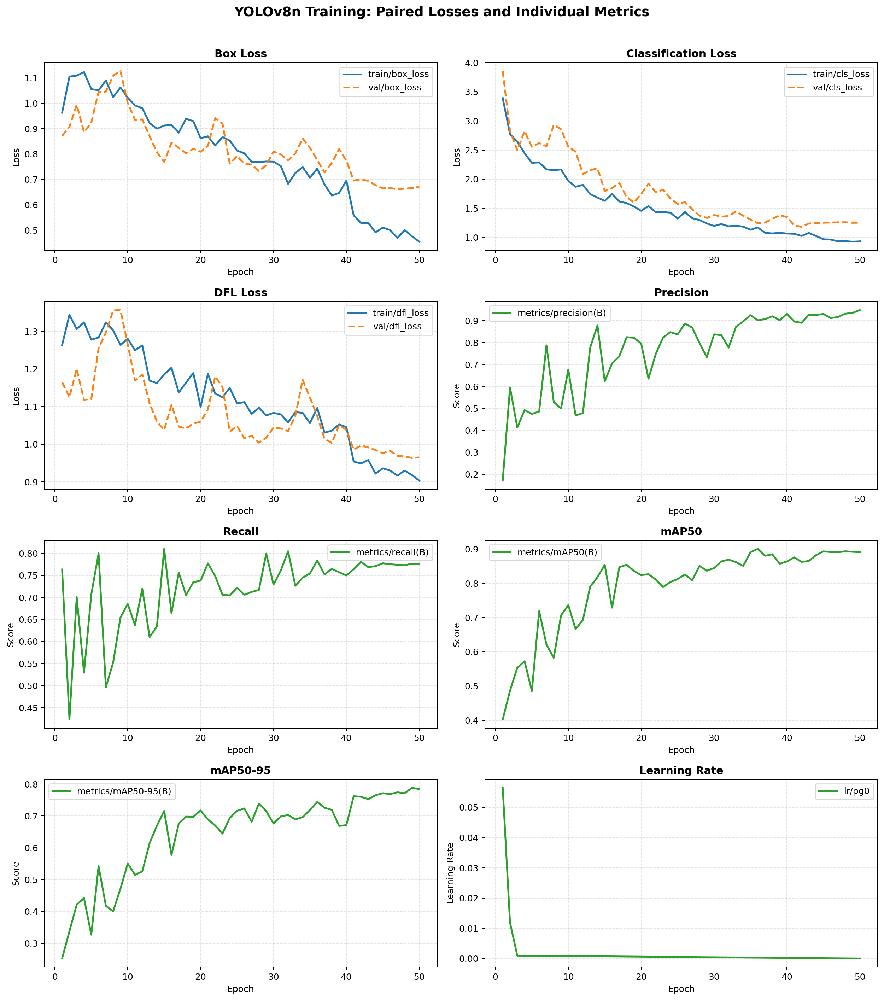

In [4]:
# ============================================================
# 9.1. DISPLAY PAIRED LOSSES AND INDIVIDUAL METRICS
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image as PILImage

# Safe import for rich notebook rendering
try:
    from IPython.display import display
except ImportError:
    display = None

# Use the training run resolved in Section 5.
if "TRAINING_RUN_DIR" not in globals():
    raise RuntimeError("Run Section 5 first to define TRAINING_RUN_DIR.")

training_run_dir = Path(TRAINING_RUN_DIR)
results_csv_path = training_run_dir / "results.csv"

if not results_csv_path.is_file():
    raise FileNotFoundError(f"Training results not found: {results_csv_path}")

df = pd.read_csv(results_csv_path)
df.columns = df.columns.str.strip()

if df.empty:
    raise ValueError(f"Training results are empty: {results_csv_path}")

# Match column names exactly, ignoring case and incidental whitespace.
normalized_columns = {
    "".join(column.split()).casefold(): column
    for column in df.columns
}

def get_column(*candidates):
    for candidate in candidates:
        key = "".join(candidate.split()).casefold()
        if key in normalized_columns:
            return normalized_columns[key]
    raise KeyError(
        f"None of these columns were found: {candidates}\n"
        f"Available columns: {list(df.columns)}"
    )

# Preserve epoch numbers recorded in results.csv.
if "epoch" in normalized_columns:
    epoch_column = normalized_columns["epoch"]
    recorded_epochs = pd.to_numeric(
        df[epoch_column], errors="coerce"
    ).to_numpy(dtype=float)
    fallback_epochs = np.arange(1, len(df) + 1, dtype=float)
    epochs = np.where(
        np.isfinite(recorded_epochs), recorded_epochs, fallback_epochs
    )
else:
    epochs = np.arange(1, len(df) + 1, dtype=float)

# Each loss subplot contains only its matching Train/Val pair.
loss_plots = [
    ("Box Loss", "train/box_loss", "val/box_loss"),
    ("Classification Loss", "train/cls_loss", "val/cls_loss"),
    ("DFL Loss", "train/dfl_loss", "val/dfl_loss"),
]

# Each remaining metric occupies a separate subplot.
metric_plots = [
    ("Precision", ("metrics/precision(B)", "metrics/precision")),
    ("Recall", ("metrics/recall(B)", "metrics/recall")),
    ("mAP50", ("metrics/mAP50(B)", "metrics/mAP50")),
    ("mAP50-95", ("metrics/mAP50-95(B)", "metrics/mAP50-95")),
    ("Learning Rate", ("lr/pg0", "lr/pg1", "lr/pg2", "lr")),
]

# Optimized figure size to render cleanly inside Jupyter output cells
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for index, (title, train_name, val_name) in enumerate(loss_plots):
    ax = axes[index]

    train_column = get_column(train_name)
    val_column = get_column(val_name)

    train_values = pd.to_numeric(
        df[train_column], errors="coerce"
    ).to_numpy(dtype=float)
    val_values = pd.to_numeric(
        df[val_column], errors="coerce"
    ).to_numpy(dtype=float)

    ax.plot(
        epochs, train_values,
        label=train_name, color="#1f77b4", linewidth=2
    )
    ax.plot(
        epochs, val_values,
        label=val_name, color="#ff7f0e",
        linestyle="--", linewidth=2
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Loss")
    ax.legend(loc="best")

for index, (title, candidates) in enumerate(metric_plots, start=3):
    ax = axes[index]
    column = get_column(*candidates)

    values = pd.to_numeric(
        df[column], errors="coerce"
    ).to_numpy(dtype=float)

    ax.plot(
        epochs, values,
        label=column, color="#2ca02c", linewidth=2
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel("Learning Rate" if title == "Learning Rate" else "Score")
    ax.legend(loc="best")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle="--", alpha=0.35)

fig.suptitle(
    "YOLOv8n Training: Paired Losses and Individual Metrics",
    fontsize=15,
    fontweight="bold",
)
fig.tight_layout(rect=(0, 0, 1, 0.97))

# 1. Save high-resolution figure to disk
output_path = training_run_dir / "structured_training_metrics.png"
fig.savefig(output_path, dpi=180, bbox_inches="tight")
print(f"Saved custom plot to: {output_path}\n")

# 2. Render persistently via PIL Image inside Jupyter output
if display is not None:
    with PILImage.open(output_path) as img:
        display(img)
else:
    plt.show()

plt.close(fig)


In [5]:
metrics = model.val()
box_metrics = metrics.box


Ultralytics 8.3.241  Python-3.10.11 torch-2.9.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv8n_minitraffic summary (fused): 72 layers, 3,007,208 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 393.2171.3 MB/s, size: 59.1 KB)
val: Scanning D:\resume\13 - mini teraffic\main\result\yolo_dataset\val\labels.cache... 22 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22 21.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0s/it 4.1s<10.4s
                   all         22         42      0.936      0.776      0.894      0.795
               bicycle          3          4          1        0.8      0.995      0.794
                   bus          6          7       0.98      0.857      0.855      0.696
                   car          3         12          1      0.202      0.623      0.517
            motorcycle          1          1      0.924          1  

In [6]:
# ============================================================
# 13. EXTRACT PER-CLASS AVERAGE PRECISION
# Robust against scalar, missing, and differently shaped AP outputs
# ============================================================

import numpy as np
import pandas as pd

print("\n" + "=" * 80)
print("PER-CLASS AVERAGE PRECISION")
print("=" * 80)

# Safe check for box_metrics and class variables definition
box_metrics = globals().get("box_metrics", None)
num_classes = globals().get("NUM_CLASSES", len(globals().get("CLASS_NAMES", [])))
class_names = globals().get("CLASS_NAMES", [])

ap_values_raw = getattr(box_metrics, "ap", None) if box_metrics is not None else None
ap_class_indices_raw = getattr(box_metrics, "ap_class_index", None) if box_metrics is not None else None

if box_metrics is None or ap_values_raw is None:
    print("\n[Warning] 'box_metrics' or its 'ap' attribute is not defined in memory.")
    print("Ensure the evaluation cell (e.g., model.val()) has been executed successfully.")
    
    # Fallback to an empty DataFrame containing configured classes
    per_class_rows = [
        {
            "class_id": i,
            "class_name": class_names[i] if i < len(class_names) else f"class_{i}",
            "AP50": np.nan,
            "AP50_95": np.nan,
            "num_iou_thresholds_reported": 0,
        }
        for i in range(num_classes if num_classes > 0 else 1)
    ]
    per_class_df = pd.DataFrame(per_class_rows)
else:
    ap_values = np.asarray(ap_values_raw, dtype=float)

    # Case 1: a single scalar AP value.
    if ap_values.ndim == 0:
        ap_values = ap_values.reshape(1, 1)
    # Case 2: a one-dimensional AP array.
    elif ap_values.ndim == 1:
        if (
            ap_class_indices_raw is not None
            and np.asarray(ap_class_indices_raw).size == 1
            and ap_values.size > 1
        ):
            ap_values = ap_values.reshape(1, -1)
        else:
            ap_values = ap_values.reshape(-1, 1)
    # Case 3: expected format is [number_of_classes, IoU_thresholds].
    elif ap_values.ndim > 2:
        ap_values = ap_values.reshape(ap_values.shape[0], -1)

    if ap_class_indices_raw is not None:
        ap_class_indices = np.asarray(ap_class_indices_raw, dtype=int).reshape(-1)
    else:
        ap_class_indices = np.arange(ap_values.shape[0], dtype=int)

    if len(ap_class_indices) != ap_values.shape[0]:
        print("\nWARNING: AP rows and class indices have different lengths.")
        print(f"AP rows       : {ap_values.shape[0]}")
        print(f"Class indices : {len(ap_class_indices)}")
        raise ValueError("Cannot safely map AP values to class IDs. Inspect box_metrics.ap and box_metrics.ap_class_index.")

    per_class_rows = []
    for row_index, class_id in enumerate(ap_class_indices):
        if num_classes > 0 and not (0 <= int(class_id) < num_classes):
            print(f"Skipping invalid AP class ID: {class_id}")
            continue

        class_ap = np.atleast_1d(np.asarray(ap_values[row_index], dtype=float)).reshape(-1)
        valid_ap = class_ap[np.isfinite(class_ap)]

        ap50_value = float(class_ap[0]) if class_ap.size > 0 and np.isfinite(class_ap[0]) else np.nan
        ap50_95_value = float(np.mean(valid_ap)) if valid_ap.size > 0 else np.nan

        c_name = class_names[int(class_id)] if int(class_id) < len(class_names) else f"class_{class_id}"

        per_class_rows.append({
            "class_id": int(class_id),
            "class_name": c_name,
            "AP50": ap50_value,
            "AP50_95": ap50_95_value,
            "num_iou_thresholds_reported": int(class_ap.size),
        })

    per_class_df = pd.DataFrame(
        per_class_rows,
        columns=["class_id", "class_name", "AP50", "AP50_95", "num_iou_thresholds_reported"]
    )

    reported_ids = set(per_class_df["class_id"].tolist()) if not per_class_df.empty else set()
    missing_class_rows = []
    for class_id, class_name in enumerate(class_names):
        if class_id not in reported_ids:
            missing_class_rows.append({
                "class_id": class_id,
                "class_name": class_name,
                "AP50": np.nan,
                "AP50_95": np.nan,
                "num_iou_thresholds_reported": 0,
            })

    if missing_class_rows:
        per_class_df = pd.concat([per_class_df, pd.DataFrame(missing_class_rows)], ignore_index=True)

    per_class_df = per_class_df.sort_values("class_id").reset_index(drop=True)

print(
    per_class_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}" if pd.notna(value) else "NaN"
    )
)



PER-CLASS AVERAGE PRECISION
 class_id    class_name   AP50  AP50_95  num_iou_thresholds_reported
        0       bicycle 0.7943   0.7943                            1
        1           bus 0.6965   0.6965                            1
        2           car 0.5172   0.5172                            1
        3    motorcycle 0.9950   0.9950                            1
        4        person 0.9950   0.9950                            1
        5     stop_sign 0.9950   0.9950                            1
        6 traffic_light 0.6258   0.6258                            1
        7         truck 0.7378   0.7378                            1



TEST EVALUATION PLOTS
Using evaluation directory: C:\Users\ASUS\runs\detect\val5


[Displaying]: confusion_matrix.png


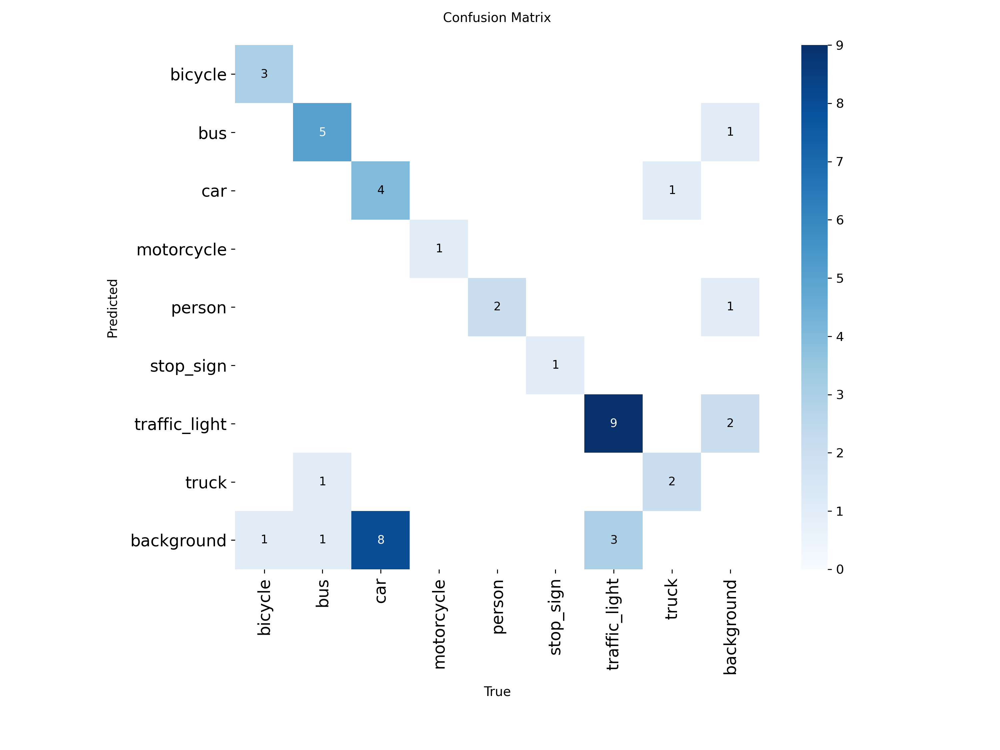


[Displaying]: confusion_matrix_normalized.png


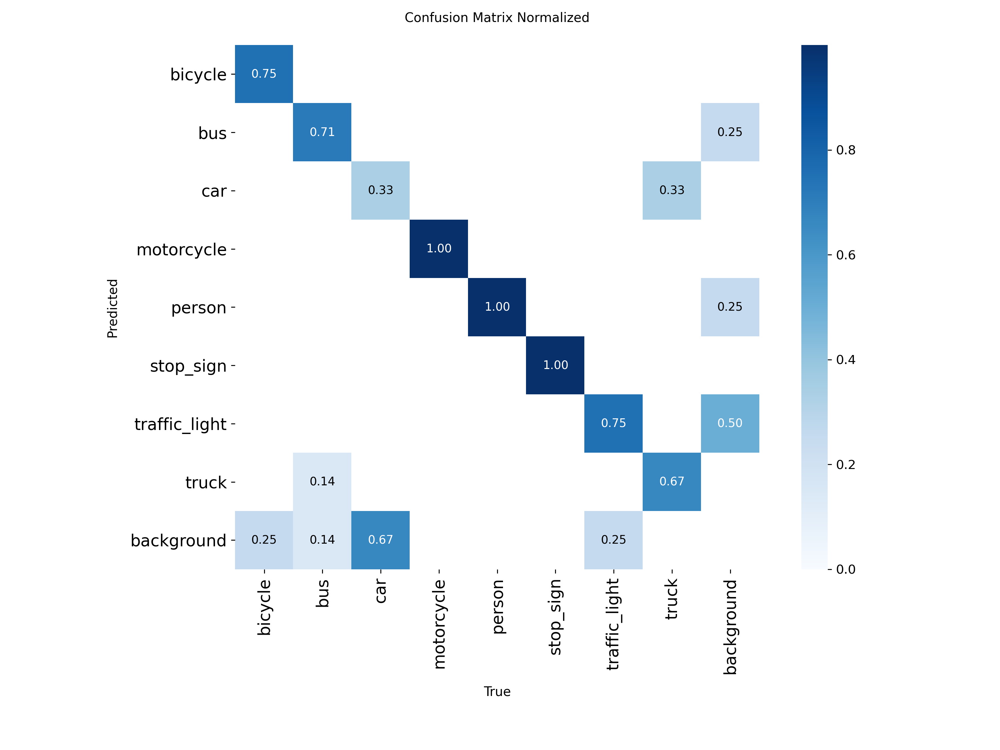

Plot not found: PR_curve.png
Plot not found: F1_curve.png
Plot not found: P_curve.png
Plot not found: R_curve.png


In [7]:
# ============================================================
# 11.1. DISPLAY TEST EVALUATION PLOTS
# Robust path resolver against missing EVALUATION_RUN_DIR
# ============================================================

from pathlib import Path
from IPython.display import display
from PIL import Image as PILImage

print("\n" + "=" * 80)
print("TEST EVALUATION PLOTS")
print("=" * 80)

# Resolve EVALUATION_RUN_DIR safely from memory or disk
eval_dir = globals().get("EVALUATION_RUN_DIR", None)

if eval_dir is None:
    # Attempt 1: check if an evaluation metrics object exists with a save_dir
    metrics_obj = globals().get("metrics", None)
    if metrics_obj is not None and hasattr(metrics_obj, "save_dir"):
        eval_dir = Path(metrics_obj.save_dir)
    else:
        # Attempt 2: fallback to standard Ultralytics / Project evaluation run paths
        base_dir = globals().get("PROJECT_ROOT", Path(r"D:\resume\13 - mini teraffic\main"))
        candidates = [
            Path(base_dir) / "runs" / "val",
            Path(base_dir) / "runs" / "detect" / "val",
            Path("runs/detect/val"),
            Path("runs/val"),
        ]
        
        # Check training run dir if evaluation plots were saved directly inside it
        training_run_dir = globals().get("TRAINING_RUN_DIR", None)
        if training_run_dir is not None:
            candidates.insert(0, Path(training_run_dir))
            candidates.insert(1, Path(training_run_dir) / "val")

        # Find the latest existing directory among candidates
        for cand in candidates:
            if cand.exists():
                # If there are subdirectories (like val, val2, val3), pick the latest
                subdirs = [p for p in cand.glob("*") if p.is_dir()]
                if subdirs:
                    subdirs.sort(key=lambda x: x.stat().st_mtime, reverse=True)
                    eval_dir = subdirs[0]
                    break
                else:
                    eval_dir = cand
                    break

if eval_dir is not None:
    eval_dir = Path(eval_dir)
    globals()["EVALUATION_RUN_DIR"] = eval_dir  # Cache for downstream cells
    print(f"Using evaluation directory: {eval_dir.resolve()}\n")
else:
    print("[Warning] Could not automatically locate EVALUATION_RUN_DIR.")
    print("Please ensure the evaluation step (e.g. model.val()) has been run.")

evaluation_plot_names = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
]

if eval_dir is not None and eval_dir.is_dir():
    found_any = False
    for plot_name in evaluation_plot_names:
        plot_path = eval_dir / plot_name

        if plot_path.is_file():
            found_any = True
            print(f"\n[Displaying]: {plot_name}")
            with PILImage.open(plot_path) as image:
                display(image.copy())
        else:
            print(f"Plot not found: {plot_name}")
            
    if not found_any:
        print("\nNote: None of the standard evaluation plot files were found in this directory.")
else:
    print("Evaluation directory does not exist or is invalid. Skipping plot display.")


PHASE 8 - SINGLE IMAGE INFERENCE
Image path  : D:\resume\13 - mini teraffic\main\img\bicycle1.jpg
Image size  : 640
Confidence  : 0.25
NMS IoU     : 0.6
Device      : 0

Selected trained model:
Phase 6 summary : D:\resume\13 - mini teraffic\main\result\training\phase6_yolov8n_20261101_210939\phase6_training_summary.json
Checkpoint      : D:\resume\13 - mini teraffic\main\result\training\phase6_yolov8n_20261101_210939\weights\best.pt
Dataset YAML    : D:\resume\13 - mini teraffic\main\result\yolo_dataset\data.yaml

Class mapping:
 0: bicycle
 1: bus
 2: car
 3: motorcycle
 4: person
 5: stop_sign
 6: traffic_light
 7: truck

Loading trained YOLO model...
Model loaded successfully.

--------------------------------------------------------------------------------
INFERENCE INPUT
--------------------------------------------------------------------------------
File          : bicycle1.jpg
Original size : 800 x 600

----------------------------------------------------------------------------

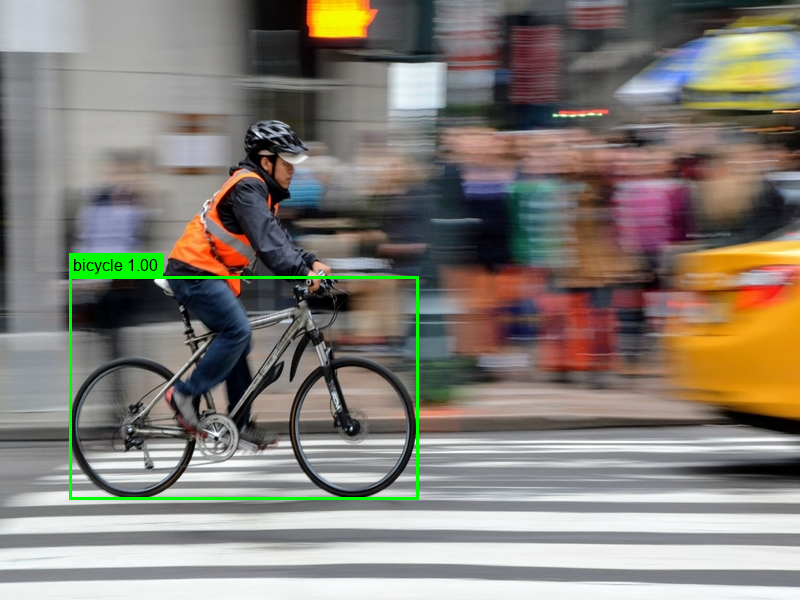


PHASE 8 - INFERENCE COMPLETED
Input image    : D:\resume\13 - mini teraffic\main\img\bicycle1.jpg
Checkpoint     : D:\resume\13 - mini teraffic\main\result\training\phase6_yolov8n_20261101_210939\weights\best.pt
Detections     : 1
Output folder  : D:\resume\13 - mini teraffic\main\result\inference\phase8_inference_20261102_110519

PHASE 8 FINISHED.


In [3]:

# ============================================================
# PHASE 8 - SINGLE IMAGE INFERENCE
# Mini Traffic Object Detection
#
# Input:
#   Image path
#
# Pipeline:
#   Load image -> YOLO preprocessing -> Inference
#   -> Original-image bounding boxes -> Class labels
#
# Outputs:
#   - Annotated image displayed in Jupyter
#   - Annotated image saved to disk
#   - Detection results saved as JSON
#
# Jupyter cell: no main() function
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import torch

from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from ultralytics import YOLO


# ============================================================
# 2. CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(
    r"D:\resume\13 - mini teraffic\main"
)

RESULT_DIR = PROJECT_ROOT / "result"
TRAINING_DIR = RESULT_DIR / "training"
INFERENCE_DIR = RESULT_DIR / "inference"

IMAGE_SIZE = 640
CONFIDENCE_THRESHOLD = 0.25
NMS_IOU_THRESHOLD = 0.60

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Change this path to the image you want to test.
IMAGE_PATH = Path(
    r"D:\resume\13 - mini teraffic\main\img\bicycle1.jpg"
)

# If True, saves the annotated image and JSON results.
SAVE_RESULTS = True

RUN_TIMESTAMP = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

INFERENCE_RUN_DIR = (
    INFERENCE_DIR
    / f"phase8_inference_{RUN_TIMESTAMP}"
)

print("=" * 80)
print("PHASE 8 - SINGLE IMAGE INFERENCE")
print("=" * 80)

print(f"Image path  : {IMAGE_PATH}")
print(f"Image size  : {IMAGE_SIZE}")
print(f"Confidence  : {CONFIDENCE_THRESHOLD}")
print(f"NMS IoU     : {NMS_IOU_THRESHOLD}")
print(f"Device      : {DEVICE}")


# ============================================================
# 3. FIND THE LATEST PHASE 6 TRAINING SUMMARY
# ============================================================

if not TRAINING_DIR.is_dir():
    raise FileNotFoundError(
        f"Training directory not found:\n{TRAINING_DIR}"
    )

summary_candidates = []

for summary_path in TRAINING_DIR.glob(
    "*/phase6_training_summary.json"
):
    try:
        with open(
            summary_path,
            "r",
            encoding="utf-8"
        ) as file:
            summary_data = json.load(file)

        if summary_data.get("phase") == 6:
            summary_candidates.append(
                (summary_path, summary_data)
            )

    except (OSError, json.JSONDecodeError) as error:
        print(
            f"Skipping invalid summary: {summary_path}\n"
            f"Reason: {error}"
        )

if not summary_candidates:
    raise FileNotFoundError(
        "No valid Phase 6 training summary was found."
    )

summary_candidates.sort(
    key=lambda item: (
        item[1].get("finished_at", ""),
        item[0].stat().st_mtime,
    ),
    reverse=True,
)

PHASE6_SUMMARY_PATH, PHASE6_SUMMARY = (
    summary_candidates[0]
)

BEST_MODEL_PATH = Path(
    PHASE6_SUMMARY.get("best_checkpoint", "")
)

if not BEST_MODEL_PATH.is_file():

    training_run_dir = Path(
        PHASE6_SUMMARY.get("run_dir", "")
    )

    BEST_MODEL_PATH = (
        training_run_dir / "weights" / "best.pt"
    )

if not BEST_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Trained checkpoint best.pt was not found.\n"
        f"Resolved path: {BEST_MODEL_PATH}"
    )

DATA_YAML_PATH = Path(
    PHASE6_SUMMARY.get("data_yaml", "")
)

if not DATA_YAML_PATH.is_file():

    dataset_dir = Path(
        PHASE6_SUMMARY.get("dataset_dir", "")
    )

    DATA_YAML_PATH = dataset_dir / "data.yaml"

if not DATA_YAML_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset YAML not found:\n{DATA_YAML_PATH}"
    )

print("\nSelected trained model:")
print(f"Phase 6 summary : {PHASE6_SUMMARY_PATH}")
print(f"Checkpoint      : {BEST_MODEL_PATH}")
print(f"Dataset YAML    : {DATA_YAML_PATH}")


# ============================================================
# 4. LOAD CLASS NAMES
# ============================================================

import yaml

with open(
    DATA_YAML_PATH,
    "r",
    encoding="utf-8"
) as file:
    dataset_config = yaml.safe_load(file)

NUM_CLASSES = int(dataset_config["nc"])
names_data = dataset_config["names"]

if isinstance(names_data, dict):
    CLASS_NAMES = [
        str(names_data.get(str(i), names_data.get(i, i)))
        for i in range(NUM_CLASSES)
    ]

elif isinstance(names_data, list):
    CLASS_NAMES = [
        str(name) for name in names_data
    ]

else:
    raise ValueError(
        "Unsupported class names format in data.yaml."
    )

print("\nClass mapping:")

for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_id:2d}: {class_name}")


# ============================================================
# 5. LOAD MODEL
# ============================================================

if not IMAGE_PATH.is_file():
    raise FileNotFoundError(
        f"Input image not found:\n{IMAGE_PATH}"
    )

print("\nLoading trained YOLO model...")

model = YOLO(
    str(BEST_MODEL_PATH),
    task="detect"
)

print("Model loaded successfully.")


# ============================================================
# 6. DEFINE INFERENCE FUNCTION
# ============================================================

def run_inference(
    image_path,
    model,
    class_names,
    output_dir=None,
    image_size=640,
    confidence_threshold=0.25,
    iou_threshold=0.60,
    device=None,
    save_results=True,
    line_width=3,
):
    """
    Run object detection on one image.

    Parameters
    ----------
    image_path : str or pathlib.Path
        Path to the input image.

    model : ultralytics.YOLO
        Loaded trained YOLO model.

    class_names : list[str]
        Names indexed by model class ID.

    output_dir : str or pathlib.Path, optional
        Directory for saved results.

    image_size : int
        YOLO inference image size.

    confidence_threshold : float
        Minimum confidence for retained detections.

    iou_threshold : float
        NMS IoU threshold.

    device : int or str, optional
        CUDA device index or "cpu".

    save_results : bool
        Save annotated image and detection JSON.

    line_width : int
        Bounding-box line thickness.

    Returns
    -------
    dict
        Original image, annotated image, detections,
        and output file paths.
    """

    # --------------------------------------------------------
    # A. Validate inputs
    # --------------------------------------------------------

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image not found:\n{image_path}"
        )

    if not (0.0 <= confidence_threshold <= 1.0):
        raise ValueError(
            "confidence_threshold must be between 0 and 1."
        )

    if not (0.0 <= iou_threshold <= 1.0):
        raise ValueError(
            "iou_threshold must be between 0 and 1."
        )

    if image_size <= 0:
        raise ValueError(
            "image_size must be a positive integer."
        )

    # --------------------------------------------------------
    # B. Read original image
    # --------------------------------------------------------

    with Image.open(image_path) as source_image:
        original_image = source_image.convert("RGB")

    original_width, original_height = original_image.size

    print("\n" + "-" * 80)
    print("INFERENCE INPUT")
    print("-" * 80)

    print(f"File          : {image_path.name}")
    print(f"Original size : {original_width} x {original_height}")

    # --------------------------------------------------------
    # C. Run model inference
    #
    # Ultralytics performs its standard preprocessing:
    # resize/letterbox, tensor conversion and normalization.
    #
    # Results boxes are mapped back to original-image
    # coordinates by Ultralytics.
    # --------------------------------------------------------

    prediction_kwargs = {
        "source": str(image_path),
        "imgsz": image_size,
        "conf": confidence_threshold,
        "iou": iou_threshold,
        "verbose": False,
        "save": False,
    }

    if device is not None:
        prediction_kwargs["device"] = device

    prediction_results = model.predict(
        **prediction_kwargs
    )

    if not prediction_results:
        raise RuntimeError(
            "The model did not return any prediction result."
        )

    result = prediction_results[0]

    # --------------------------------------------------------
    # D. Extract bounding boxes and class predictions
    # --------------------------------------------------------

    detections = []

    boxes = result.boxes

    if boxes is not None and len(boxes) > 0:

        xyxy_array = (
            boxes.xyxy.detach()
            .cpu()
            .numpy()
        )

        confidence_array = (
            boxes.conf.detach()
            .cpu()
            .numpy()
        )

        class_id_array = (
            boxes.cls.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        for box_xyxy, confidence, class_id in zip(
            xyxy_array,
            confidence_array,
            class_id_array,
        ):

            x1, y1, x2, y2 = [
                float(value)
                for value in box_xyxy
            ]

            class_id = int(class_id)

            if not (
                0 <= class_id < len(class_names)
            ):
                class_name = f"class_{class_id}"
            else:
                class_name = class_names[class_id]

            # Clip coordinates to the original image bounds.
            x1 = max(0.0, min(x1, original_width))
            x2 = max(0.0, min(x2, original_width))
            y1 = max(0.0, min(y1, original_height))
            y2 = max(0.0, min(y2, original_height))

            if x2 <= x1 or y2 <= y1:
                continue

            detections.append({
                "class_id": class_id,
                "class_name": class_name,
                "confidence": float(confidence),
                "x1": round(x1, 2),
                "y1": round(y1, 2),
                "x2": round(x2, 2),
                "y2": round(y2, 2),
                "box_width": round(x2 - x1, 2),
                "box_height": round(y2 - y1, 2),
            })

    # --------------------------------------------------------
    # E. Draw boxes and class names on original-size image
    # --------------------------------------------------------

    annotated_image = original_image.copy()
    draw = ImageDraw.Draw(annotated_image)

    try:
        font = ImageFont.truetype(
            "arial.ttf",
            size=max(16, original_width // 70)
        )
    except OSError:
        font = ImageFont.load_default()

    for detection in detections:

        x1 = int(round(detection["x1"]))
        y1 = int(round(detection["y1"]))
        x2 = int(round(detection["x2"]))
        y2 = int(round(detection["y2"]))

        label = (
            f'{detection["class_name"]} '
            f'{detection["confidence"]:.2f}'
        )

        # Draw bounding box.
        draw.rectangle(
            [x1, y1, x2, y2],
            outline=(0, 255, 0),
            width=line_width,
        )

        # Compute label dimensions.
        text_bbox = draw.textbbox(
            (0, 0),
            label,
            font=font,
        )

        text_width = text_bbox[2] - text_bbox[0]
        text_height = text_bbox[3] - text_bbox[1]

        label_top = max(
            0,
            y1 - text_height - 8
        )

        label_right = min(
            original_width,
            x1 + text_width + 8
        )

        # Filled label background.
        draw.rectangle(
            [
                x1,
                label_top,
                label_right,
                label_top + text_height + 8,
            ],
            fill=(0, 255, 0),
        )

        draw.text(
            (x1 + 4, label_top + 3),
            label,
            fill=(0, 0, 0),
            font=font,
        )

    # --------------------------------------------------------
    # F. Print detection report
    # --------------------------------------------------------

    print("\n" + "-" * 80)
    print("DETECTION RESULTS")
    print("-" * 80)

    print(f"Detections found: {len(detections)}")

    if detections:

        detections_df = pd.DataFrame(detections)

        print(
            detections_df[
                [
                    "class_id",
                    "class_name",
                    "confidence",
                    "x1",
                    "y1",
                    "x2",
                    "y2",
                ]
            ].to_string(index=False)
        )

    else:
        print(
            "No objects were detected above the confidence threshold."
        )

    # --------------------------------------------------------
    # G. Save outputs
    # --------------------------------------------------------

    saved_image_path = None
    saved_json_path = None

    if save_results:

        if output_dir is None:
            output_dir = (
                Path(image_path).parent
                / "inference_results"
            )

        output_dir = Path(output_dir)

        output_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        saved_image_path = (
            output_dir
            / f"{image_path.stem}_prediction.jpg"
        )

        saved_json_path = (
            output_dir
            / f"{image_path.stem}_detections.json"
        )

        # Prevent overwriting previous results.
        if saved_image_path.exists() or saved_json_path.exists():

            timestamp = datetime.now().strftime(
                "%Y%m%d_%H%M%S_%f"
            )

            saved_image_path = (
                output_dir
                / f"{image_path.stem}_prediction_{timestamp}.jpg"
            )

            saved_json_path = (
                output_dir
                / f"{image_path.stem}_detections_{timestamp}.json"
            )

        annotated_image.save(
            saved_image_path,
            quality=95
        )

        output_data = {
            "input_image": str(image_path.resolve()),
            "original_width": original_width,
            "original_height": original_height,
            "model_checkpoint": str(
                getattr(model, "ckpt_path", "") or ""
            ),
            "image_size": image_size,
            "confidence_threshold": confidence_threshold,
            "iou_threshold": iou_threshold,
            "num_detections": len(detections),
            "detections": detections,
        }

        with open(
            saved_json_path,
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(
                output_data,
                file,
                ensure_ascii=False,
                indent=2,
                allow_nan=False,
            )

        print("\nSaved outputs:")
        print(f"Annotated image : {saved_image_path}")
        print(f"Detection JSON  : {saved_json_path}")

    # --------------------------------------------------------
    # H. Display annotated image
    # --------------------------------------------------------

    print("\nAnnotated image:")
    display(annotated_image)

    return {
        "input_path": str(image_path),
        "original_size": (
            original_width,
            original_height
        ),
        "num_detections": len(detections),
        "detections": detections,
        "annotated_image": annotated_image,
        "saved_image_path": (
            str(saved_image_path)
            if saved_image_path is not None
            else None
        ),
        "saved_json_path": (
            str(saved_json_path)
            if saved_json_path is not None
            else None
        ),
    }


# ============================================================
# 7. RUN INFERENCE
# ============================================================

INFERENCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if INFERENCE_RUN_DIR.exists():
    raise FileExistsError(
        f"Inference output directory already exists:\n"
        f"{INFERENCE_RUN_DIR}"
    )

INFERENCE_RUN_DIR.mkdir(
    parents=True,
    exist_ok=False
)

inference_output = run_inference(
    image_path=IMAGE_PATH,
    model=model,
    class_names=CLASS_NAMES,
    output_dir=INFERENCE_RUN_DIR,
    image_size=IMAGE_SIZE,
    confidence_threshold=CONFIDENCE_THRESHOLD,
    iou_threshold=NMS_IOU_THRESHOLD,
    device=DEVICE,
    save_results=SAVE_RESULTS,
    line_width=3,
)


# ============================================================
# 8. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("PHASE 8 - INFERENCE COMPLETED")
print("=" * 80)

print(f"Input image    : {IMAGE_PATH}")
print(f"Checkpoint     : {BEST_MODEL_PATH}")
print(f"Detections     : {inference_output['num_detections']}")
print(f"Output folder  : {INFERENCE_RUN_DIR}")

print("\nPHASE 8 FINISHED.")


--------------------------------------------------------------------------------
INFERENCE INPUT
--------------------------------------------------------------------------------
File          : bicycle28.jpg
Original size : 800 x 600

--------------------------------------------------------------------------------
DETECTION RESULTS
--------------------------------------------------------------------------------
Detections found: 5
 class_id    class_name  confidence     x1     y1     x2     y2
        6 traffic_light    0.998660 241.23   0.00 304.92 135.12
        0       bicycle    0.994441 419.64 383.83 709.82 588.33
        6 traffic_light    0.986472 140.68   0.77 193.74 119.68
        6 traffic_light    0.809666 239.02 228.88 263.49 343.88
        4        person    0.763614  26.39 271.92 145.98 543.86

Saved outputs:
Annotated image : D:\resume\13 - mini teraffic\main\result\inference\phase8_inference_20261102_110519\bicycle28_prediction.jpg
Detection JSON  : D:\resume\13 - mini

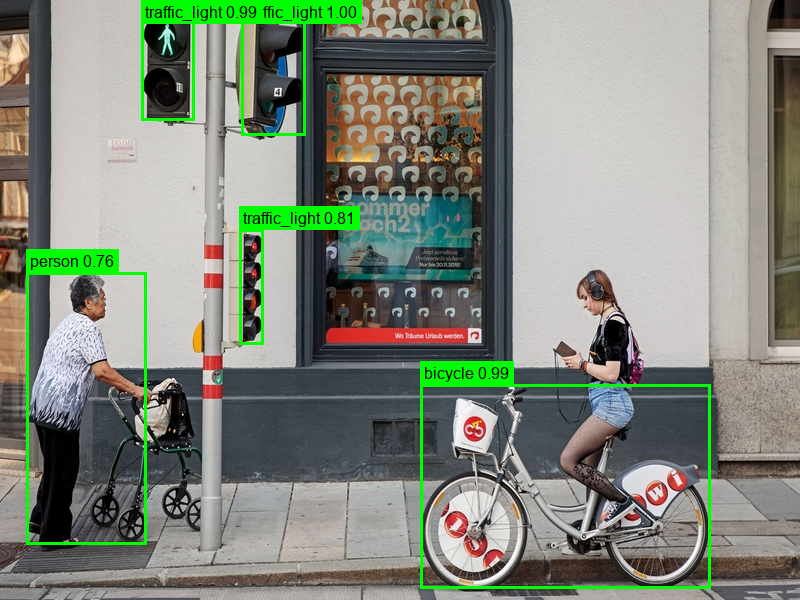

In [4]:
inference_output = run_inference(
    image_path=r"D:\resume\13 - mini teraffic\main\result\splits\test\images\bicycle28.jpg",
    model=model,
    class_names=CLASS_NAMES,
    output_dir=INFERENCE_RUN_DIR,
    image_size=IMAGE_SIZE,
    confidence_threshold=CONFIDENCE_THRESHOLD,
    iou_threshold=NMS_IOU_THRESHOLD,
    device=DEVICE,
    save_results=SAVE_RESULTS,
    line_width=3,
)
